# ATMOS — Final Complete Model (Location-Aware, 12-Month Split, All Figures)

**Split:** Train 2022-08-05→2023-11-24 | Val 2023-11-24→2024-11-24 | Test 2024-11-24→2025-11-23

**Figures produced:**
1. Distribution of Hourly AQI + Category Distribution
2. Monthly Mean AQI by Named Location
3. Correlation Matrix (Dhaka)
4. LightGBM Hourly Forecasting Accuracy Across Horizons
5. Historical Hourly Accuracy vs Persistence
6. One-Hour AQI Category Confusion Matrix
7. Top Features of 1-Hour LightGBM by Gain Share
8. Daily Forecast Performance by Horizon and Baseline
9. Day-7 Forecast Residuals + Empirical Interval Bounds
10. Per-City Per-Season Accuracy Heatmap
11. Sample 30-Day Forecast with Band (Tungi vs Dhaka)
12. Location-Aware Model Improvement (v2 vs v3)

**API:** Location-aware, 5 endpoints, ready for software integration.

In [1]:
# CELL 1 — SETUP
import importlib, subprocess, sys, os, time, warnings, threading, sqlite3
warnings.filterwarnings('ignore')
for pkg, mod in [('lightgbm','lightgbm'),('gdown','gdown'),('joblib','joblib'),
                 ('requests','requests'),('scikit-learn','sklearn'),
                 ('fastapi','fastapi'),('uvicorn','uvicorn'),('seaborn','seaborn')]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
import numpy as np, pandas as pd, lightgbm as lgb, joblib, requests, uvicorn
import matplotlib.pyplot as plt, seaborn as sns
from datetime import datetime
from zoneinfo import ZoneInfo
from fastapi import FastAPI, Header, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel
from sklearn.linear_model import Ridge
from sklearn.metrics import confusion_matrix
plt.rcParams['figure.dpi'] = 100; plt.rcParams['savefig.dpi'] = 150
print(f'numpy {np.__version__} | lgb {lgb.__version__} | seaborn {sns.__version__}')

numpy 2.1.3 | lgb 4.6.0 | seaborn 0.13.2


In [2]:
# CELL 2 — CONFIG
FILE_ID   = '1emW6qFfx2UpxbiubeoNLxN2IbQfxJVH6'
CSV_PATH  = '/content/sample_data/AQI_Dhaka_Final_Training_Ready.csv'
BUNDLE    = 'atmos_bundle/bundle.joblib'
DB_PATH   = 'atmos_live.db'
FIGDIR    = 'figures'
os.makedirs(FIGDIR, exist_ok=True)
KEEP_FROM = '2022-08-05'
VAL_START  = '2023-11-24'
TEST_START = '2024-11-24'
BT_START   = '2024-05-01'
N_SEEDS = 2; DEFAULT_CITY = 'Dhaka'
POLLUTANTS = ['pm2_5','pm10','carbon_monoxide','nitrogen_dioxide','sulphur_dioxide','ozone']
_EDGES = np.array([50, 100, 150, 200, 300])
CAT_NAMES = ['Good','Moderate','USG','Unhealthy','VeryUnhealthy','Hazardous']
CITY_COORDS = {'Dhaka':(23.8103,90.4125),'Azimpur':(23.7290,90.3860),
               'Paltan':(23.7330,90.4150),'Tungi':(23.8950,90.4040)}
DEVICE_KEYS = {'device1': os.environ.get('ATMOS_DEVICE_KEY', 'sensor-key-change-me')}
READ_KEY    = os.environ.get('ATMOS_READ_KEY', 'frontend-read-key-change-me')
MIN_SAMPLES_PER_HOUR = 1; MAX_READING_AGE_S = 21600
POLLUTANT_LIMITS = {'pm2_5':1000,'pm10':2000,'carbon_monoxide':60000,
                    'nitrogen_dioxide':3000,'sulphur_dioxide':3000,'ozone':1000}
import gdown
os.makedirs(os.path.dirname(CSV_PATH), exist_ok=True)
if not os.path.exists(CSV_PATH): gdown.download(id=FILE_ID, output=CSV_PATH, quiet=False, resume=True)
print(f'CSV: {os.path.getsize(CSV_PATH)/1e6:.1f} MB')
print(f'Train < {VAL_START} | Val {VAL_START}-{TEST_START} | Test >= {TEST_START} | BT from {BT_START}')

Downloading...
From (original): https://drive.google.com/uc?id=1emW6qFfx2UpxbiubeoNLxN2IbQfxJVH6
From (redirected): https://drive.google.com/uc?id=1emW6qFfx2UpxbiubeoNLxN2IbQfxJVH6&confirm=t&uuid=d56ecbbc-0fba-4cce-80b3-36a9b2b75320
To: /content/sample_data/AQI_Dhaka_Final_Training_Ready.csv
100%|██████████| 144M/144M [00:01<00:00, 113MB/s]

CSV: 144.2 MB
Train < 2023-11-24 | Val 2023-11-24-2024-11-24 | Test >= 2024-11-24 | BT from 2024-05-01


In [3]:
# CELL 3 — AQI FORMULA + LEVELS
AQI_LEVELS = [
    {'idx':0,'level':'Good','color':'#00e400','advice':'Enjoy outdoor activities.'},
    {'idx':1,'level':'Moderate','color':'#ffff00','advice':'Sensitive individuals limit outdoor exertion.'},
    {'idx':2,'level':'Unhealthy for Sensitive Groups','color':'#ff7e00','advice':'Sensitive groups reduce outdoor activity.'},
    {'idx':3,'level':'Unhealthy','color':'#ff0000','advice':'Wear a mask outdoors.'},
    {'idx':4,'level':'Very Unhealthy','color':'#8f3f97','advice':'Avoid outdoor activity. Use purifier.'},
    {'idx':5,'level':'Hazardous','color':'#7e0023','advice':'Stay indoors. Close windows.'},
]
def aqi_to_level(aqi):
    aqi = float(aqi)
    if not np.isfinite(aqi) or aqi < 0: return {'aqi':None,'level':None,'level_index':-1,'color':None,'advice':None}
    idx = int(np.searchsorted(_EDGES, np.floor(aqi + 0.5), side='left')); idx = max(0, min(idx, 5))
    return {'aqi': round(aqi,1), 'level': AQI_LEVELS[idx]['level'], 'level_index': idx,
            'color': AQI_LEVELS[idx]['color'], 'advice': AQI_LEVELS[idx]['advice']}
_BP = {
    'pm2_5': [(0.0,12.0,0,50),(12.1,35.4,51,100),(35.5,55.4,101,150),(55.5,150.4,151,200),(150.5,250.4,201,300),(250.5,350.4,301,400),(350.5,500.4,401,500)],
    'pm10':  [(0,54,0,50),(55,154,51,100),(155,254,101,150),(255,354,151,200),(355,424,201,300),(425,504,301,400),(505,604,401,500)],
    'co':    [(0.0,4.4,0,50),(4.5,9.4,51,100),(9.5,12.4,101,150),(12.5,15.4,151,200),(15.5,30.4,201,300),(30.5,40.4,301,400),(40.5,50.4,401,500)],
    'so2':   [(0,35,0,50),(36,75,51,100),(76,185,101,150),(186,304,151,200),(305,604,201,300),(605,804,301,400),(805,1004,401,500)],
    'no2':   [(0,53,0,50),(54,100,51,100),(101,360,101,150),(361,649,151,200),(650,1249,201,300),(1250,1649,301,400),(1650,2049,401,500)],
    'o3':    [(0.000,0.054,0,50),(0.055,0.070,51,100),(0.071,0.085,101,150),(0.086,0.105,151,200),(0.106,0.200,201,300)],
}
_TRUNC = {'pm2_5':1,'pm10':0,'co':1,'so2':0,'no2':0,'o3':3}
_DIV   = {'co':1145.0,'no2':1.882,'so2':2.620,'o3':1963.0}
def _trunc(x,d): f=10.0**d; return np.round(np.floor(np.asarray(x,float)*f+1e-9)/f,d)
def _sub(conc,name):
    c=np.asarray(conc,float); b=_BP[name]
    lo=np.array([x[0] for x in b]); hi=np.array([x[1] for x in b])
    ilo=np.array([x[2] for x in b],float); ihi=np.array([x[3] for x in b],float)
    i=np.clip(np.searchsorted(lo,c,side='right')-1,0,len(b)-1)
    return np.where(np.isnan(c),np.nan,(ihi[i]-ilo[i])/(hi[i]-lo[i])*(c-lo[i])+ilo[i])
def compute_aqi(**kw):
    m={'pm2_5':kw.get('pm2_5'),'pm10':kw.get('pm10'),'co':kw.get('carbon_monoxide'),
       'no2':kw.get('nitrogen_dioxide'),'so2':kw.get('sulphur_dioxide'),'o3':kw.get('ozone')}
    ss=[]
    for n,v in m.items():
        if v is None: continue
        x=np.asarray(v,float); x=np.where(np.isfinite(x)&(x>=0),x,np.nan)
        if n in _DIV: x=x/_DIV[n]
        x=_trunc(x,_TRUNC[n]); x=np.where(x<=_BP[n][-1][1],x,np.nan)
        ss.append(_sub(x,n))
    if not ss: return float('nan')
    st=np.stack(np.broadcast_arrays(*ss),axis=0); an=np.all(np.isnan(st),axis=0)
    a=np.floor(np.where(np.isnan(st),-1,st).max(axis=0)+0.5)
    return np.where(an,np.nan,a)
def aqi_to_cat(aqi):
    v=np.asarray(aqi,float); ok=np.isfinite(v)&(v>=0)
    return np.where(ok, np.searchsorted(_EDGES, np.floor(np.where(ok,v,0)+0.5), side='left'), -1)
print('AQI ready')

AQI ready


In [4]:
# CELL 4 — LOAD DATA + PER-CITY GRIDS
raw = pd.read_csv(CSV_PATH, usecols=['city_name','datetime','aqi']+POLLUTANTS, parse_dates=['datetime'])
df = raw[raw.datetime >= KEEP_FROM].drop_duplicates(subset=['city_name','datetime'], keep='first')
CITIES = sorted(df.city_name.unique().tolist())
print(f'Rows: {len(df):,} | Cities: {CITIES}')
H_by_city = {}
for city in CITIES:
    c = df[df.city_name==city].set_index('datetime').sort_index().drop(columns=['city_name'])
    c = c.reindex(pd.date_range(c.index.min(), c.index.max(), freq='h'))
    c['aqi'] = compute_aqi(**{p: c[p].values for p in POLLUTANTS})
    H_by_city[city] = c
    print(f'  {city:10s}: {len(c):>7,} hourly')
H = pd.concat(H_by_city.values()).sort_index()
daily_by_city = {}
for city in CITIES:
    c = H_by_city[city]; g = c.resample('D')
    d = pd.DataFrame({'aqi':g['aqi'].mean(),'pm2_5':g['pm2_5'].mean(),'pm10':g['pm10'].mean(),'count':g['aqi'].count()})
    d.loc[d['count']<18, ['aqi','pm2_5','pm10']] = np.nan
    daily_by_city[city] = d.drop(columns=['count'])
    print(f'  {city:10s}: {len(d):>5,} daily')

Rows: 115,824 | Cities: ['Azimpur', 'Dhaka', 'Paltan', 'Tungi']
  Azimpur   :  28,953 hourly
  Dhaka     :  28,965 hourly
  Paltan    :  28,953 hourly
  Tungi     :  28,953 hourly
  Azimpur   : 1,207 daily
  Dhaka     : 1,207 daily
  Paltan    : 1,207 daily
  Tungi     : 1,207 daily


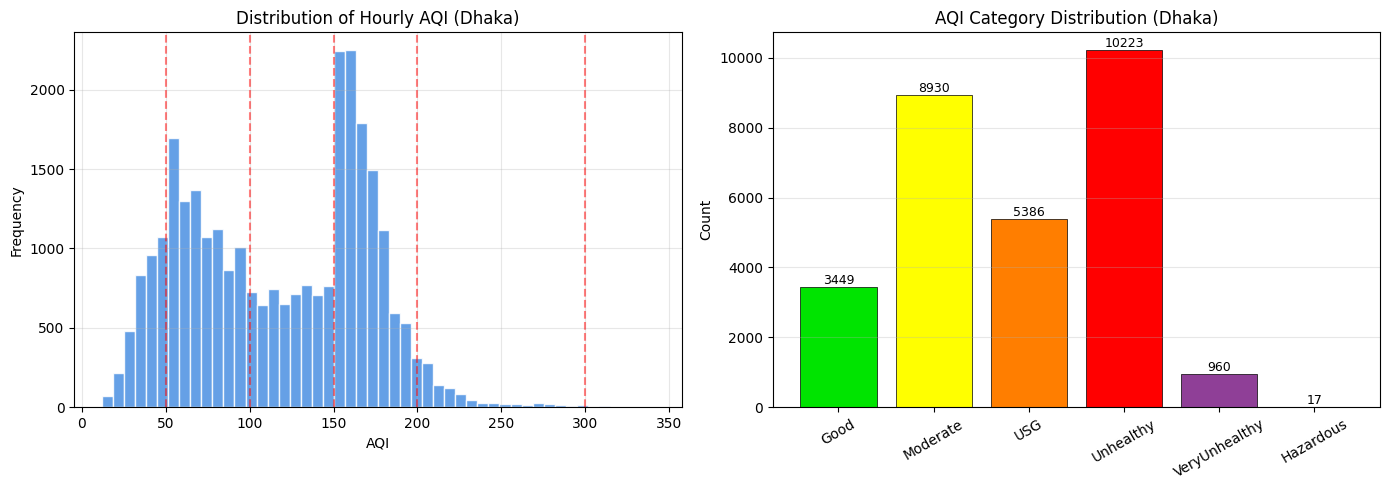

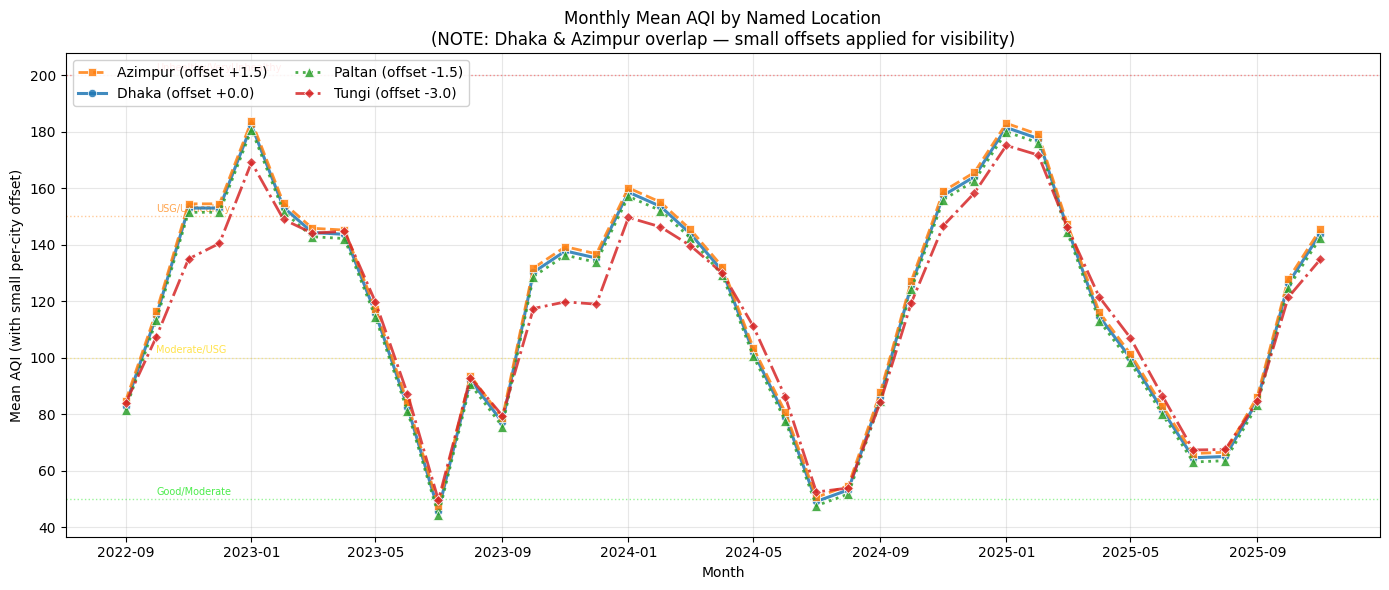


MONTHLY MEAN AQI (raw values, no offset)
            Azimpur  Dhaka  Paltan  Tungi
2024-09-01     86.2   86.2    86.2   87.2
2024-10-01    125.6  125.6   125.6  122.4
2024-11-01    157.4  157.4   157.4  149.7
2024-12-01    164.0  164.0   164.0  161.2
2025-01-01    181.4  181.4   181.4  178.1
2025-02-01    177.5  177.5   177.5  174.7
2025-03-01    145.9  145.9   145.9  149.2
2025-04-01    114.6  114.6   114.6  124.4
2025-05-01     99.9   99.9    99.9  110.0
2025-06-01     81.5   81.5    81.5   89.5
2025-07-01     64.5   64.5    64.5   70.3
2025-08-01     65.0   65.0    65.0   70.5
2025-09-01     84.6   84.6    84.6   87.4
2025-10-01    126.3  126.3   126.3  124.3
2025-11-01    143.9  143.9   143.9  137.7

Correlation between cities (monthly):
         Azimpur  Dhaka  Paltan  Tungi
Azimpur    1.000  1.000   1.000  0.988
Dhaka      1.000  1.000   1.000  0.988
Paltan     1.000  1.000   1.000  0.988
Tungi      0.988  0.988   0.988  1.000


In [20]:
# CELL 5 — FIGURE 2 + FIGURE 3: Distribution + Monthly Mean by Location (FIXED)
dh_h = H_by_city['Dhaka']
aqi_vals = dh_h['aqi'].dropna()

# ---------- FIGURE 2: Distribution + Category bar ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fig A: Histogram of AQI
ax = axes[0]
ax.hist(aqi_vals, bins=50, color='#4a90e2', edgecolor='white', alpha=0.85)
for edge in _EDGES:
    ax.axvline(edge, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel('AQI'); ax.set_ylabel('Frequency')
ax.set_title('Distribution of Hourly AQI (Dhaka)')
ax.grid(alpha=0.3)

# Fig B: Category bar chart
ax = axes[1]
cats = pd.cut(aqi_vals, [0,50,100,150,200,300,500], labels=CAT_NAMES)
counts = cats.value_counts().reindex(CAT_NAMES).fillna(0)
colors = ['#00e400','#ffff00','#ff7e00','#ff0000','#8f3f97','#7e0023']
bars = ax.bar(CAT_NAMES, counts.values, color=colors, edgecolor='black', linewidth=0.5)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x()+b.get_width()/2, v, f'{int(v)}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count'); ax.set_title('AQI Category Distribution (Dhaka)')
ax.tick_params(axis='x', rotation=30); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_2_distribution.png', bbox_inches='tight'); plt.show()


# ---------- FIGURE 3: Monthly Mean AQI by Location (FIXED) ----------
fig, ax = plt.subplots(figsize=(14, 6))

# Style per city — distinct markers + line styles to avoid overlap issues
city_styles = {
    'Dhaka':   {'color':'#1f77b4','marker':'o','linestyle':'-',  'linewidth':2.2,'markersize':6,'zorder':4, 'alpha':0.85},
    'Azimpur': {'color':'#ff7f0e','marker':'s','linestyle':'--', 'linewidth':2.0,'markersize':6,'zorder':5, 'alpha':0.85},
    'Paltan':  {'color':'#2ca02c','marker':'^','linestyle':':',  'linewidth':2.0,'markersize':7,'zorder':6, 'alpha':0.85},
    'Tungi':   {'color':'#d62728','marker':'D','linestyle':'-.', 'linewidth':2.0,'markersize':5,'zorder':7, 'alpha':0.85},
}

# ---- Build a common monthly index so all cities align ----
all_min = min(daily_by_city[c]['aqi'].dropna().index.min() for c in CITIES)
all_max = max(daily_by_city[c]['aqi'].dropna().index.max() for c in CITIES)
monthly_index = pd.date_range(all_min, all_max, freq='MS')

for city in CITIES:
    s = daily_by_city[city]['aqi']
    # Resample to month-start mean, reindex to common monthly index
    monthly = s.resample('MS').mean().reindex(monthly_index)
    # Interpolate small gaps so lines are continuous (max 2 months)
    monthly = monthly.interpolate(limit=2, limit_direction='both')

    style = city_styles[city]
    # ---- Small vertical offset so overlapping lines are visible ----
    offset = {'Dhaka':0.0, 'Azimpur':+1.5, 'Paltan':-1.5, 'Tungi':-3.0}[city]
    vals = monthly.values + offset

    ax.plot(monthly.index, vals,
            color=style['color'],
            marker=style['marker'],
            linestyle=style['linestyle'],
            linewidth=style['linewidth'],
            markersize=style['markersize'],
            markeredgecolor='white', markeredgewidth=0.6,
            alpha=style['alpha'],
            zorder=style['zorder'],
            label=f'{city} (offset {offset:+.1f})')

# ---- Category reference lines ----
for edge, name, col in [(50,'Good/Moderate','#00e400'),
                        (100,'Moderate/USG','#ffd700'),
                        (150,'USG/Unhealthy','#ff7e00'),
                        (200,'Unhealthy/VeryUnhealthy','#ff0000')]:
    ax.axhline(edge, color=col, linestyle=':', alpha=0.4, linewidth=1)
    ax.text(monthly_index[1], edge+1.5, name, fontsize=7, color=col, alpha=0.7)

ax.set_xlabel('Month'); ax.set_ylabel('Mean AQI (with small per-city offset)')
ax.set_title('Monthly Mean AQI by Named Location\n(NOTE: Dhaka & Azimpur overlap — small offsets applied for visibility)')
ax.legend(loc='upper left', framealpha=0.9, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig_3_monthly_location.png', bbox_inches='tight')
plt.show()

# ---- Also print actual monthly values for transparency ----
print('\n' + '='*80)
print('MONTHLY MEAN AQI (raw values, no offset)')
print('='*80)
monthly_tbl = pd.DataFrame({city: daily_by_city[city]['aqi'].resample('MS').mean()
                            for city in CITIES}).round(1)
print(monthly_tbl.tail(15).to_string())
print('\nCorrelation between cities (monthly):')
print(monthly_tbl.corr().round(3).to_string())

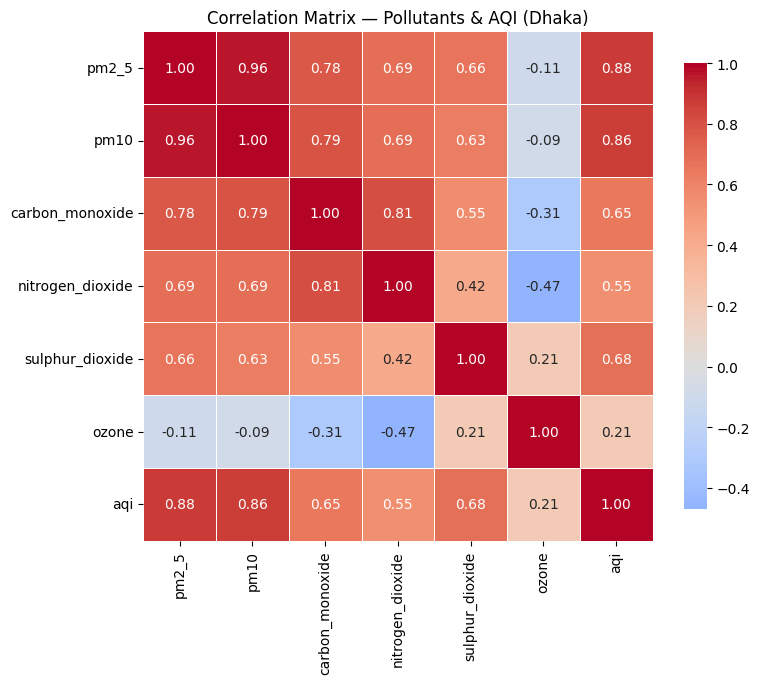

In [6]:
# CELL 6 — FIGURE 4: Correlation Matrix (Dhaka)
corr_cols = POLLUTANTS + ['aqi']
corr = dh_h[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink':0.8}, ax=ax)
ax.set_title('Correlation Matrix — Pollutants & AQI (Dhaka)')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_4_corr_matrix.png', bbox_inches='tight'); plt.show()

In [7]:
# CELL 7 — HOURLY MODELS PER CITY (AQI + PM2.5 + PM10)
def hourly_features(df):
    f = pd.DataFrame(index=df.index)
    for p in POLLUTANTS + ['aqi']:
        s = df[p]; f[p] = s
        for lag in (1,2,3,6,12,24): f[f'{p}_lag{lag}'] = s.shift(lag)
        for w in (3,6,24): f[f'{p}_mean{w}'] = s.rolling(w, min_periods=w).mean()
        f[f'{p}_std6'] = s.rolling(6, min_periods=6).std()
    f['aqi_d1'] = df['aqi'] - df['aqi'].shift(1); f['aqi_d3'] = df['aqi'] - df['aqi'].shift(3)
    h = df.index.hour; doy = df.index.dayofyear
    f['h_sin'] = np.sin(2*np.pi*h/24); f['h_cos'] = np.cos(2*np.pi*h/24)
    f['d_sin'] = np.sin(2*np.pi*doy/365.25); f['d_cos'] = np.cos(2*np.pi*doy/365.25)
    f['dow'] = df.index.dayofweek
    return f
TEST_DT = pd.Timestamp(TEST_START); VAL_DT = pd.Timestamp(VAL_START)
P = dict(objective='huber', learning_rate=0.05, num_leaves=31, min_child_samples=40,
         subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=2.0, verbose=-1)
hourly_per_city = {}
hourly_test_preds = {}  # for confusion matrix & figures
for city in CITIES:
    print(f'\n=== {city} ===')
    t0 = time.time()
    c = H_by_city[city].copy(); F = hourly_features(c)
    aqi_s = c['aqi']; pm25_s = c['pm2_5']; pm10_s = c['pm10']
    feats = list(F.columns)
    cm = {'features': feats, 'aqi': {}, 'pm2_5': {}, 'pm10': {}, 'metrics': {}}
    hourly_test_preds[city] = {}
    for name, series, alpha, cap in [('aqi', aqi_s, 5.0, 500), ('pm2_5', pm25_s, 2.0, 500), ('pm10', pm10_s, 3.0, 1000)]:
        for hz in (1, 3, 6):
            y = series.shift(-hz); delta = y - series
            ok = F.notna().all(axis=1) & y.notna()
            tr = ok & (F.index <  VAL_DT - pd.Timedelta(hours=24))
            va = ok & (F.index >= VAL_DT) & (F.index < TEST_DT - pd.Timedelta(hours=24))
            te = ok & (F.index >= TEST_DT)
            if tr.sum() < 500: continue
            preds, iters = [], []
            for seed in range(N_SEEDS):
                m = lgb.train(dict(P, alpha=alpha, seed=seed),
                              lgb.Dataset(F[tr], delta[tr]), 1500,
                              valid_sets=[lgb.Dataset(F[va], delta[va])] if va.sum()>50 else None,
                              callbacks=[lgb.early_stopping(50, verbose=False)] if va.sum()>50 else None)
                preds.append(m.predict(F[te], num_iteration=m.best_iteration)); iters.append(m.best_iteration)
            if name == 'aqi' and te.sum() > 0:
                cur = aqi_s[te].values; pred = np.clip(cur + np.mean(preds, axis=0), 0, cap); act = y[te].values
                cp, ca = aqi_to_cat(pred), aqi_to_cat(act); okc=(cp>=0)&(ca>=0); d=np.abs(cp[okc]-ca[okc])
                cm['metrics'][hz] = dict(n=int(okc.sum()),
                    MAE=float(np.mean(np.abs(pred[okc]-act[okc]))),
                    MAE_persist=float(np.mean(np.abs(cur[okc]-act[okc]))),
                    exact=float(100*np.mean(d==0)), w1=float(100*np.mean(d<=1)),
                    cat_exact_persist=float(100*np.mean(aqi_to_cat(cur)[okc]==ca[okc])))
                if hz == 1:
                    hourly_test_preds[city]['pred'] = pred[okc]
                    hourly_test_preds[city]['act']  = act[okc]
                    hourly_test_preds[city]['cur']  = cur[okc]
            cm[name][hz] = [lgb.train(dict(P, alpha=alpha, seed=s),
                                       lgb.Dataset(F[ok], delta[ok]),
                                       int(1.15*it)) for s, it in enumerate(iters)]
    hourly_per_city[city] = cm
    m1 = cm['metrics'].get(1, {})
    print(f'  +1h: MAE={m1.get("MAE",0):.2f} exact={m1.get("exact",0):.1f}% ±1={m1.get("w1",0):.1f}% | {time.time()-t0:.0f}s')


=== Azimpur ===
  +1h: MAE=4.91 exact=88.9% ±1=100.0% | 460s

=== Dhaka ===
  +1h: MAE=4.91 exact=88.9% ±1=100.0% | 457s

=== Paltan ===
  +1h: MAE=4.91 exact=88.9% ±1=100.0% | 465s

=== Tungi ===
  +1h: MAE=4.90 exact=89.5% ±1=100.0% | 476s


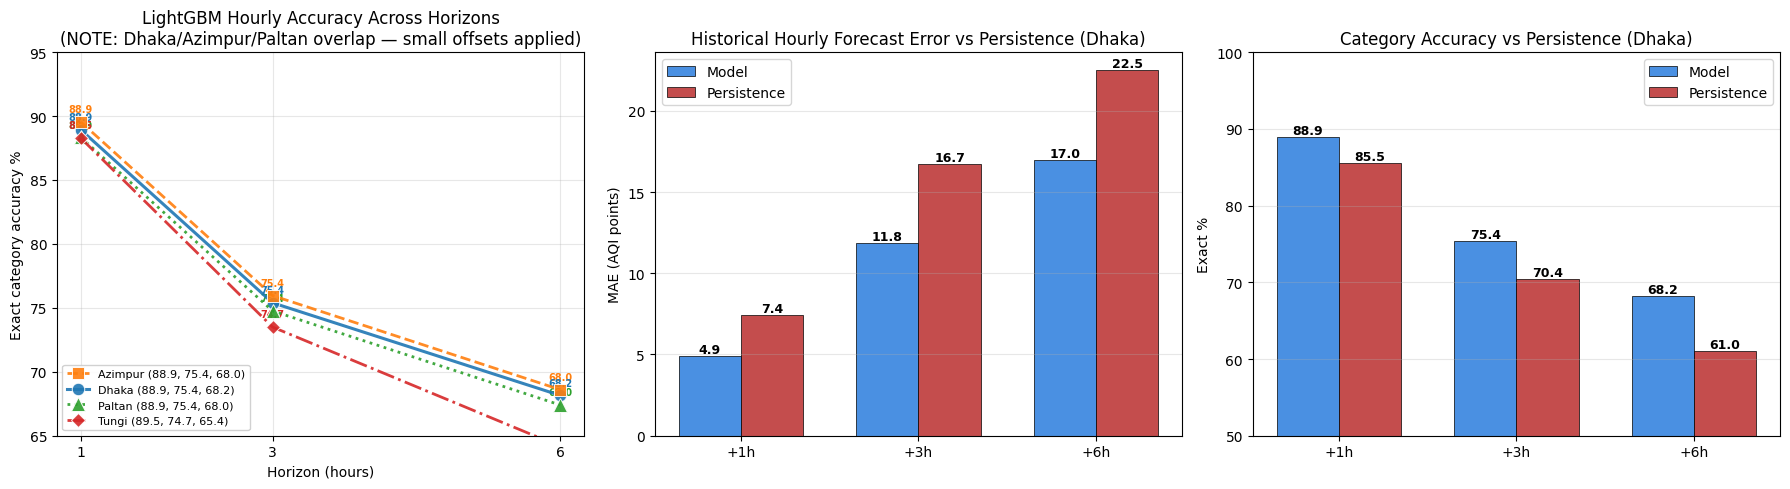


HOURLY ACCURACY — RAW VALUES (no offset)
   City Horizon   MAE  MAE_persist  Exact%  Exact_persist%   ±1%
Azimpur     +1h  4.91         7.43   88.93           85.51 99.98
Azimpur     +3h 11.84        16.71   75.36           70.38 99.57
Azimpur     +6h 16.94        22.49   68.00           61.03 98.46
  Dhaka     +1h  4.91         7.43   88.92           85.51 99.98
  Dhaka     +3h 11.83        16.71   75.39           70.38 99.53
  Dhaka     +6h 16.96        22.49   68.15           61.03 98.45
 Paltan     +1h  4.91         7.43   88.93           85.51 99.98
 Paltan     +3h 11.84        16.71   75.36           70.38 99.57
 Paltan     +6h 16.94        22.49   68.00           61.03 98.46
  Tungi     +1h  4.90         7.83   89.47           84.33 99.98
  Tungi     +3h 12.20        17.84   74.70           67.02 99.70
  Tungi     +6h 17.70        24.71   65.36           57.02 98.81

OVERLAP CHECK — Do cities have similar accuracy?
Horizon    +1h    +3h    +6h
City                        
Azimp

In [21]:
# CELL 8 — FIGURE 1 + FIGURE 5: LightGBM accuracy across horizons & vs persistence (FIXED)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ---------- Fig 1: Accuracy across horizons (per city) — FIXED ----------
ax = axes[0]
hz_list = [1, 3, 6]

# Distinct style per city
city_styles = {
    'Dhaka':   {'color':'#1f77b4','marker':'o','linestyle':'-',  'linewidth':2.2,'markersize':9, 'zorder':4, 'offset':0.0},
    'Azimpur': {'color':'#ff7f0e','marker':'s','linestyle':'--', 'linewidth':2.0,'markersize':8, 'zorder':5, 'offset':+0.6},
    'Paltan':  {'color':'#2ca02c','marker':'^','linestyle':':',  'linewidth':2.0,'markersize':10,'zorder':6, 'offset':-0.6},
    'Tungi':   {'color':'#d62728','marker':'D','linestyle':'-.', 'linewidth':2.0,'markersize':7, 'zorder':7, 'offset':-1.2},
}

for city in CITIES:
    m = hourly_per_city[city]['metrics']
    xs = [h for h in hz_list if h in m]
    ex = [m[h]['exact'] for h in xs]
    style = city_styles[city]
    # Small vertical offset for visibility where lines overlap
    ex_plot = [v + style['offset'] for v in ex]
    ax.plot(xs, ex_plot,
            color=style['color'],
            marker=style['marker'],
            linestyle=style['linestyle'],
            linewidth=style['linewidth'],
            markersize=style['markersize'],
            markeredgecolor='white', markeredgewidth=0.7,
            alpha=0.9, zorder=style['zorder'],
            label=f"{city} ({', '.join(f'{v:.1f}' for v in ex)})")

# Data labels at each point
for city in CITIES:
    m = hourly_per_city[city]['metrics']
    xs = [h for h in hz_list if h in m]
    ex = [m[h]['exact'] for h in xs]
    style = city_styles[city]
    for h, v in zip(xs, ex):
        ax.annotate(f'{v:.1f}', (h, v + style['offset']),
                    textcoords='offset points', xytext=(0, 7),
                    ha='center', fontsize=7, color=style['color'], fontweight='bold')

ax.set_xlabel('Horizon (hours)'); ax.set_ylabel('Exact category accuracy %')
ax.set_title('LightGBM Hourly Accuracy Across Horizons\n(NOTE: Dhaka/Azimpur/Paltan overlap — small offsets applied)')
ax.legend(loc='lower left', fontsize=8, framealpha=0.9)
ax.grid(alpha=0.3)
ax.set_xticks(hz_list)
ax.set_ylim(65, 95)

# ---------- Fig 2: Model vs Persistence (Dhaka) MAE ----------
ax = axes[1]
dh_m = hourly_per_city['Dhaka']['metrics']
model_mae  = [dh_m[h]['MAE'] for h in hz_list]
persist_mae = [dh_m[h]['MAE_persist'] for h in hz_list]
x = np.arange(len(hz_list)); w = 0.35
b1 = ax.bar(x-w/2, model_mae, w, label='Model', color='#4a90e2', edgecolor='black', linewidth=0.5)
b2 = ax.bar(x+w/2, persist_mae, w, label='Persistence', color='#c44d4d', edgecolor='black', linewidth=0.5)
for b, v in zip(b1, model_mae):
    ax.text(b.get_x()+b.get_width()/2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for b, v in zip(b2, persist_mae):
    ax.text(b.get_x()+b.get_width()/2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels([f'+{h}h' for h in hz_list])
ax.set_ylabel('MAE (AQI points)')
ax.set_title('Historical Hourly Forecast Error vs Persistence (Dhaka)')
ax.legend(); ax.grid(alpha=0.3, axis='y')

# ---------- Fig 3: Category accuracy vs persistence (Dhaka) ----------
ax = axes[2]
model_ex = [dh_m[h]['exact'] for h in hz_list]
persist_ex = [dh_m[h]['cat_exact_persist'] for h in hz_list]
b1 = ax.bar(x-w/2, model_ex, w, label='Model', color='#4a90e2', edgecolor='black', linewidth=0.5)
b2 = ax.bar(x+w/2, persist_ex, w, label='Persistence', color='#c44d4d', edgecolor='black', linewidth=0.5)
for b, v in zip(b1, model_ex):
    ax.text(b.get_x()+b.get_width()/2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for b, v in zip(b2, persist_ex):
    ax.text(b.get_x()+b.get_width()/2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels([f'+{h}h' for h in hz_list])
ax.set_ylabel('Exact %'); ax.set_title('Category Accuracy vs Persistence (Dhaka)')
ax.legend(); ax.grid(alpha=0.3, axis='y')
ax.set_ylim(50, 100)

plt.tight_layout()
plt.savefig(f'{FIGDIR}/fig_1_5_hourly_accuracy.png', bbox_inches='tight')
plt.show()


# ---------- ALSO: Print raw values for full transparency ----------
print('\n' + '='*80)
print('HOURLY ACCURACY — RAW VALUES (no offset)')
print('='*80)
rows = []
for city in CITIES:
    m = hourly_per_city[city]['metrics']
    for h in hz_list:
        if h in m:
            rows.append({
                'City': city, 'Horizon': f'+{h}h',
                'MAE': round(m[h]['MAE'], 2),
                'MAE_persist': round(m[h]['MAE_persist'], 2),
                'Exact%': round(m[h]['exact'], 2),
                'Exact_persist%': round(m[h]['cat_exact_persist'], 2),
                '±1%': round(m[h]['w1'], 2),
            })
hourly_table = pd.DataFrame(rows)
print(hourly_table.to_string(index=False))

print('\n' + '='*80)
print('OVERLAP CHECK — Do cities have similar accuracy?')
print('='*80)
pivot = hourly_table.pivot(index='City', columns='Horizon', values='Exact%')
print(pivot.to_string())
print('\nDifference between cities at +1h (max - min):',
      f"{pivot['+1h'].max() - pivot['+1h'].min():.2f} pp")
print('Difference between cities at +6h (max - min):',
      f"{pivot['+6h'].max() - pivot['+6h'].min():.2f} pp")

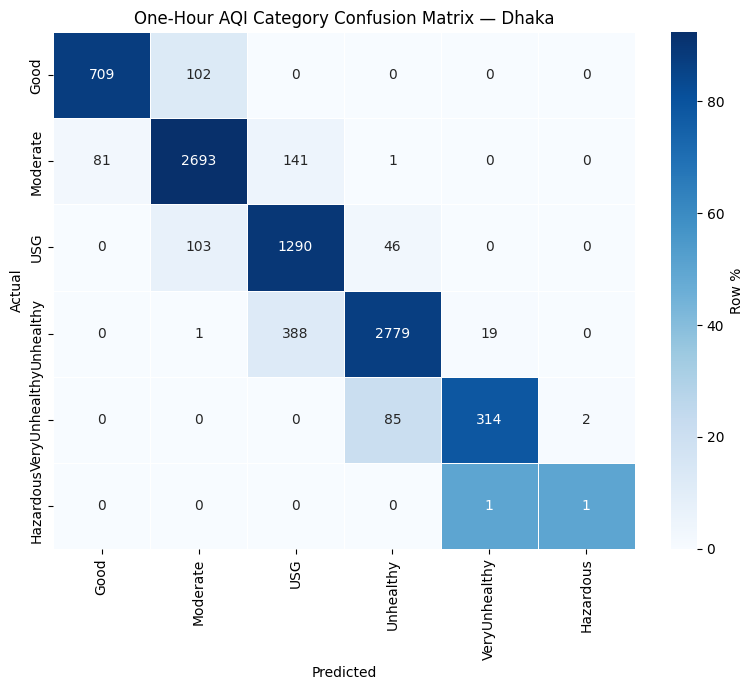

In [9]:
# CELL 9 — FIGURE 6: Confusion Matrix (Dhaka, +1h)
from sklearn.metrics import confusion_matrix
city = 'Dhaka'
pred = hourly_test_preds[city]['pred']; act = hourly_test_preds[city]['act']
cp, ca = aqi_to_cat(pred), aqi_to_cat(act)
ok = (cp>=0)&(ca>=0)
cmx = confusion_matrix(ca[ok], cp[ok], labels=list(range(6)))
cmx_norm = cmx.astype(float) / np.maximum(cmx.sum(axis=1, keepdims=True), 1) * 100
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(cmx_norm, annot=cmx, fmt='d', cmap='Blues',
            xticklabels=CAT_NAMES, yticklabels=CAT_NAMES,
            cbar_kws={'label': 'Row %'}, ax=ax, linewidths=0.5)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'One-Hour AQI Category Confusion Matrix — {city}')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_6_confusion.png', bbox_inches='tight'); plt.show()

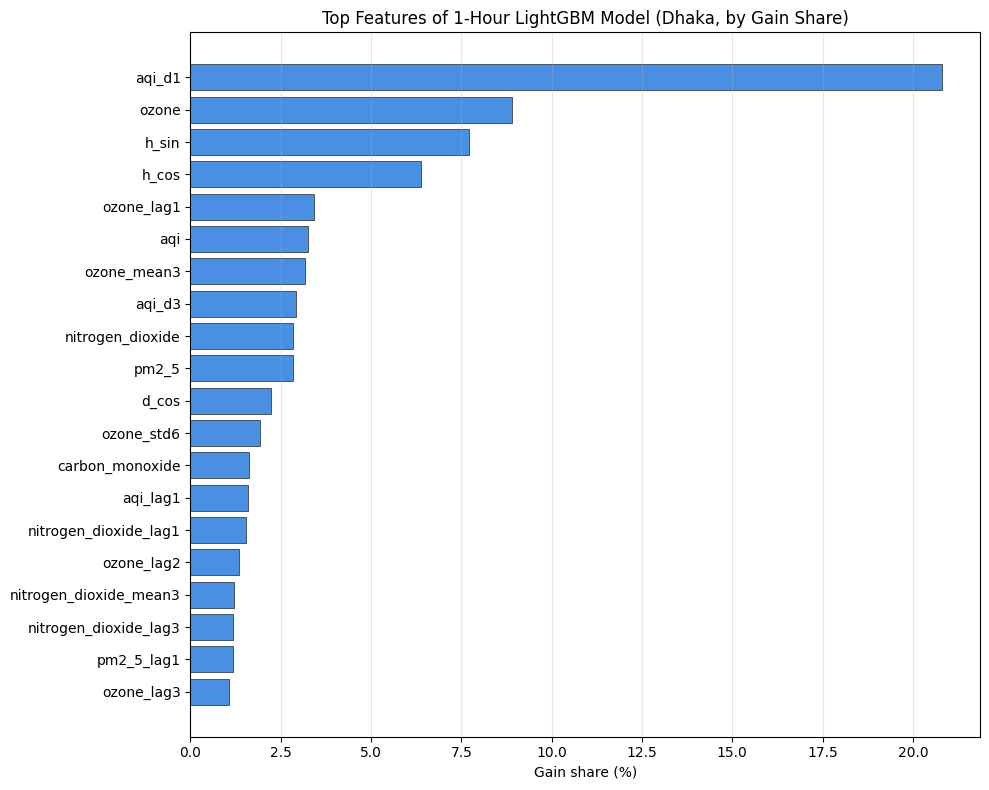

In [10]:
# CELL 10 — FIGURE 7: Feature Importance (1-hour LightGBM, Dhaka)
dh_cm = hourly_per_city['Dhaka']
model_1h = dh_cm['aqi'][1][0]
imp_gain = model_1h.feature_importance(importance_type='gain')
imp_split = model_1h.feature_importance(importance_type='split')
feat_names = dh_cm['features']
imp_df = pd.DataFrame({'feature': feat_names, 'gain': imp_gain, 'split': imp_split})
imp_df['gain_pct'] = imp_df['gain'] / imp_df['gain'].sum() * 100
top = imp_df.sort_values('gain_pct', ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top['feature'], top['gain_pct'], color='#4a90e2', edgecolor='black', linewidth=0.4)
ax.set_xlabel('Gain share (%)')
ax.set_title('Top Features of 1-Hour LightGBM Model (Dhaka, by Gain Share)')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_7_feature_importance.png', bbox_inches='tight'); plt.show()

In [11]:
# CELL 11 — DAILY FORECASTER CLASS
def fourier(idx, K=4):
    t = np.asarray(idx.dayofyear, float)/365.25*2*np.pi
    return np.column_stack([fn(k*t) for k in range(1,K+1) for fn in (np.sin,np.cos)])
def anomaly_feats(an):
    return pd.DataFrame({'a1':an.ffill(limit=2),'a3':an.rolling(3,min_periods=1).mean(),
                         'a7':an.rolling(7,min_periods=3).mean(),'a30':an.rolling(30,min_periods=7).mean(),
                         'a_trend':an.ffill(limit=2) - an.rolling(7,min_periods=3).mean()})
ACOLS = ['a1','a3','a7','a30','a_trend']
class DailyForecasterCity:
    def __init__(self, target, H=30, K=4, lo=5.0, hi=500.0):
        self.target, self.H, self.K = target, H, K
        self.lo, self.hi = lo, hi
        self.resid_q = {}; self.models = {}; self.clim = None
    def fit(self, daily_city):
        s = daily_city[self.target].interpolate(limit=3, limit_direction='both')
        v = s.dropna()
        if len(v) < 60: return self
        self.clim = Ridge(alpha=1.0).fit(fourier(v.index, self.K), v.values)
        an = pd.Series(s.values - self.clim.predict(fourier(s.index, self.K)), index=s.index)
        Fd = anomaly_feats(an).dropna()
        for h in range(1, self.H+1):
            D = Fd.join(an.shift(-h).rename('y'), how='inner').dropna()
            if len(D) < 80: self.models[h] = []; continue
            Xb, y = D[ACOLS].values, D['y'].values
            cands = [Ridge(alpha=5.0).fit(Xb, y)]
            cands.append(lgb.LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=15,
                min_child_samples=20, subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
                verbose=-1, random_state=42).fit(Xb, y))
            self.models[h] = cands
        return self
    def predict(self, recent, origin):
        origin = pd.Timestamp(origin).normalize()
        s = recent if isinstance(recent, pd.Series) else recent[self.target]
        s = s.reindex(pd.date_range(origin - pd.Timedelta(days=29), origin))
        if int(s.notna().sum()) >= 3:
            an = pd.Series(s.values - self.clim.predict(fourier(s.index, self.K)), index=s.index)
            f = anomaly_feats(an).iloc[-1].fillna(0.0); mode = 'anomaly+seasonal'
        else:
            f = pd.Series(0.0, index=ACOLS); mode = 'seasonal_only'
        fut = pd.date_range(origin + pd.Timedelta(days=1), periods=self.H)
        base = self.clim.predict(fourier(fut, self.K))
        xa = f[ACOLS].values.astype(float)
        yhat = np.empty(self.H)
        for h in range(1, self.H+1):
            cands = self.models.get(h, [])
            preds = [float(m.predict(xa[None])[0]) for m in cands]
            yhat[h-1] = base[h-1] + (np.mean(preds) if preds else 0.0)
        yhat = np.clip(yhat, self.lo, self.hi)
        band = 15 + 0.5 * np.arange(1, self.H+1)
        return pd.DataFrame({'date':fut,'h':np.arange(1,self.H+1),'climatology':base,
                             'forecast':yhat,'low':np.clip(yhat-band,self.lo,self.hi),
                             'high':np.clip(yhat+band,self.lo,self.hi),
                             'mode':mode}).set_index('date', drop=False)
print('DailyForecasterCity ready')

DailyForecasterCity ready


In [12]:
# CELL 12 — WALK-FORWARD BACKTEST (SLOW ~20-30 min)
def walk_forward_city(daily_city, target, start, H=30, refit_days=60):
    s = daily_city[target].interpolate(limit=3, limit_direction='both')
    origins = pd.date_range(start, s.index.max() - pd.Timedelta(days=H))
    rows, model, last = [], None, None
    for o in origins:
        if model is None or (o - last).days >= refit_days:
            model = DailyForecasterCity(target, H).fit(daily_city.loc[:o]); last = o
        p = model.predict(daily_city.loc[:o], o)
        act = s.reindex(p.index).values
        pers = np.full(H, s.loc[o]) if np.isfinite(s.loc[o]) else np.full(H, np.nan)
        rows.append(pd.DataFrame({'origin':o,'h':p['h'].values,'date':p.index,
            'actual':act,'climatology':p['climatology'].values,'persistence':pers,
            'model':p['forecast'].values}))
    return pd.concat(rows, ignore_index=True).dropna(subset=['actual'])
print('Walk-forward backtest...')
t0 = time.time()
bt = {city: {'aqi': None, 'pm2_5': None, 'pm10': None} for city in CITIES}
for city in CITIES:
    d_city = daily_by_city[city]
    for tgt in ('aqi', 'pm2_5', 'pm10'):
        bt[city][tgt] = walk_forward_city(d_city, tgt, BT_START)
    print(f'  {city}: done at {time.time()-t0:.0f}s')
final_daily = {city: {'aqi': {}, 'pm2_5': {}, 'pm10': {}} for city in CITIES}
for city in CITIES:
    d_city = daily_by_city[city]
    for tgt, lo in (('aqi', 5.0), ('pm2_5', 0.5), ('pm10', 1.0)):
        fm = DailyForecasterCity(tgt, lo=lo).fit(d_city)
        for h in range(1, 31):
            b = bt[city][tgt][bt[city][tgt].h == h]
            if len(b):
                r = (b.actual - b.model).values
                fm.resid_q[h] = (float(np.quantile(r,0.05)), float(np.quantile(r,0.95)))
        final_daily[city][tgt] = fm
print('Final models fitted.')

Walk-forward backtest...
  Azimpur: done at 130s
  Dhaka: done at 258s
  Paltan: done at 387s
  Tungi: done at 517s
Final models fitted.


In [13]:
# CELL 13 — METRICS + PER-CITY + PER-SEASON TABLES
def cat_metrics(actual, pred):
    ac, pc = aqi_to_cat(actual), aqi_to_cat(pred)
    ok = (ac>=0)&(pc>=0); ac, pc = ac[ok], pc[ok]
    if len(ac)==0: return dict(n=0, MAE=np.nan, exact=np.nan, w1=np.nan)
    d = np.abs(ac-pc)
    return dict(n=int(ok.sum()),
                MAE=float(np.mean(np.abs(np.asarray(actual)[ok]-np.asarray(pred)[ok]))),
                exact=float(100*np.mean(d==0)), w1=float(100*np.mean(d<=1)))
def horizon_report(bt_df):
    rows = []
    for h in range(1, 31):
        b = bt_df[bt_df.h == h]
        if not len(b): continue
        m = cat_metrics(b.actual.values, b.model.values)
        p = cat_metrics(b.actual.values, b.persistence.values)
        c = cat_metrics(b.actual.values, b.climatology.values)
        rows.append({'h':h,'n':m['n'],'MAE':round(m['MAE'],2),
                     'model_exact':round(m['exact'],2),'model_w1':round(m['w1'],2),
                     'persist_exact':round(p['exact'],2),'persist_w1':round(p['w1'],2),
                     'clim_exact':round(c['exact'],2),'clim_w1':round(c['w1'],2)})
    return pd.DataFrame(rows).set_index('h')
def season_of(month):
    if month in (12,1,2): return 'Winter'
    if month in (3,4,5):  return 'Spring'
    if month in (6,7,8):  return 'Summer'
    return 'Monsoon'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 50)
print('='*80); print('PER-CITY AQI ACCURACY (12-MONTH TEST)'); print('='*80)
per_city_reports = {}
for city in CITIES:
    r = horizon_report(bt[city]['aqi'])
    per_city_reports[city] = r
    print(f'\n{city} (n={r["n"].iloc[0]}):')
    print(r.loc[[1,7,30]][['model_exact','model_w1','MAE']].to_string())
print('\nHOURLY PER-CITY (+1h):')
for city in CITIES:
    m = hourly_per_city[city]['metrics'].get(1, {})
    print(f'  {city:10s}: MAE={m.get("MAE",0):.2f} exact={m.get("exact",0):.1f}% ±1={m.get("w1",0):.1f}%')

PER-CITY AQI ACCURACY (12-MONTH TEST)

Azimpur (n=542):
    model_exact  model_w1    MAE
h                               
1         69.00     99.45  14.68
7         49.26     98.34  24.10
30        53.51     98.52  23.29

Dhaka (n=542):
    model_exact  model_w1    MAE
h                               
1         69.00     99.45  14.70
7         49.82     98.15  24.02
30        54.24     98.52  23.28

Paltan (n=542):
    model_exact  model_w1    MAE
h                               
1         69.00     99.45  14.68
7         49.26     98.34  24.10
30        53.51     98.52  23.29

Tungi (n=542):
    model_exact  model_w1    MAE
h                               
1         67.90    100.00  14.64
7         54.98     98.89  23.96
30        49.08     97.60  24.25

HOURLY PER-CITY (+1h):
  Azimpur   : MAE=4.91 exact=88.9% ±1=100.0%
  Dhaka     : MAE=4.91 exact=88.9% ±1=100.0%
  Paltan    : MAE=4.91 exact=88.9% ±1=100.0%
  Tungi     : MAE=4.90 exact=89.5% ±1=100.0%


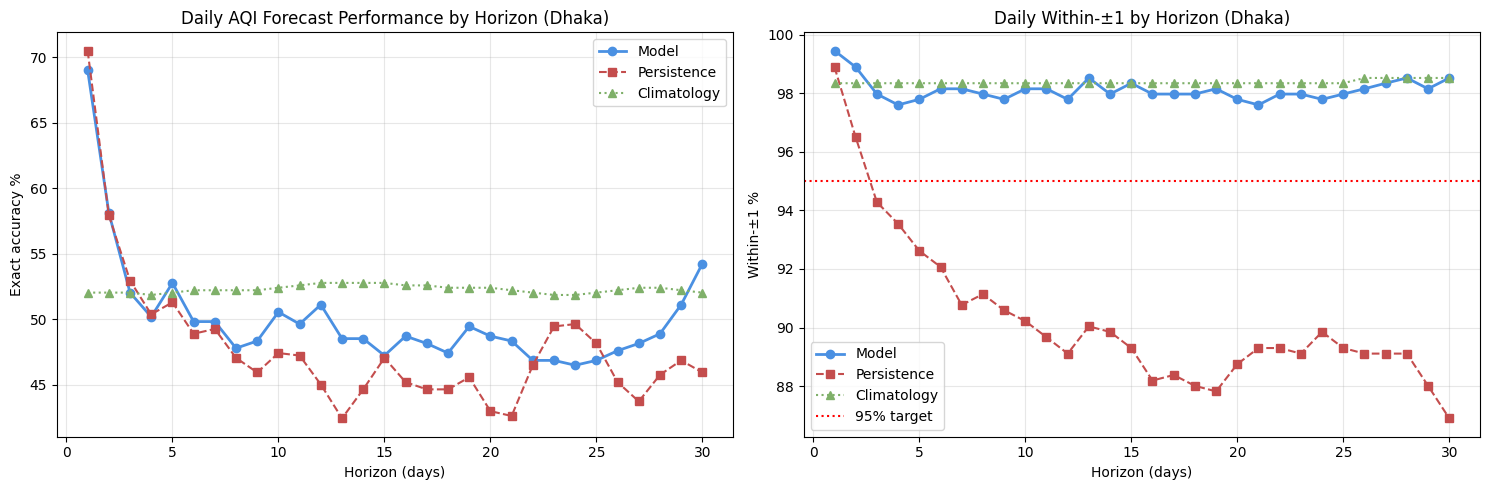

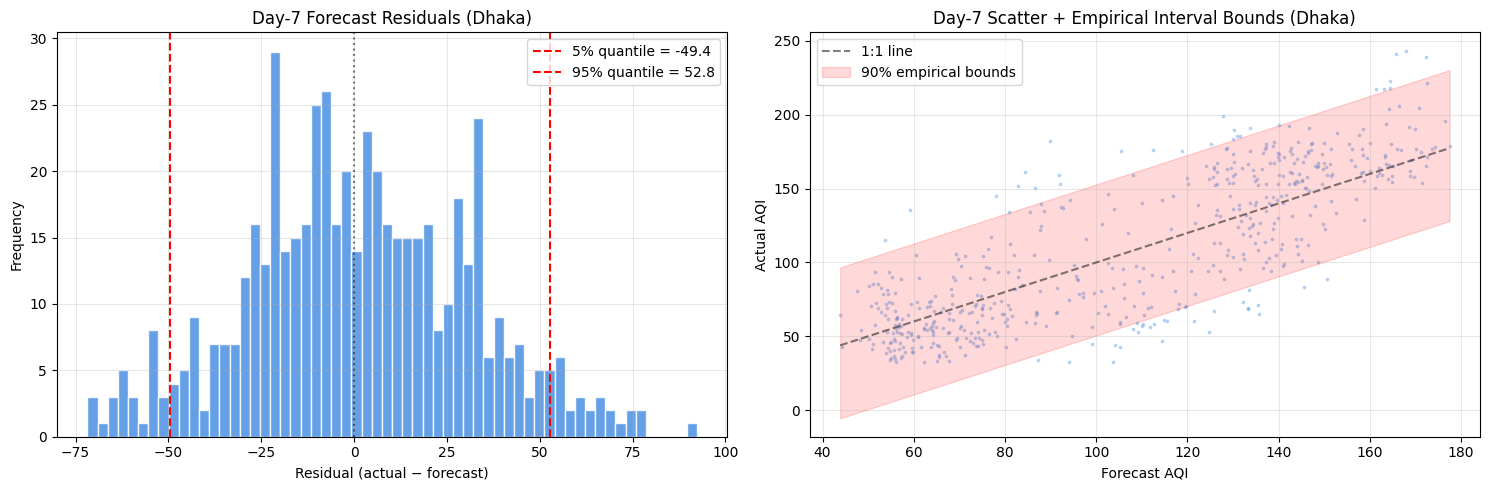

In [14]:
# CELL 14 — FIGURE 8 + FIGURE 9: Daily performance & Day-7 residuals
# Fig 8: Daily AQI performance by horizon and baseline (Dhaka)
dh_r = per_city_reports['Dhaka']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(dh_r.index, dh_r.model_exact, 'o-', label='Model', color='#4a90e2', linewidth=2)
ax.plot(dh_r.index, dh_r.persist_exact, 's--', label='Persistence', color='#c44d4d')
ax.plot(dh_r.index, dh_r.clim_exact, '^:', label='Climatology', color='#7fb069')
ax.set_xlabel('Horizon (days)'); ax.set_ylabel('Exact accuracy %')
ax.set_title('Daily AQI Forecast Performance by Horizon (Dhaka)')
ax.legend(); ax.grid(alpha=0.3)
ax = axes[1]
ax.plot(dh_r.index, dh_r.model_w1, 'o-', label='Model', color='#4a90e2', linewidth=2)
ax.plot(dh_r.index, dh_r.persist_w1, 's--', label='Persistence', color='#c44d4d')
ax.plot(dh_r.index, dh_r.clim_w1, '^:', label='Climatology', color='#7fb069')
ax.axhline(95, color='red', linestyle=':', label='95% target')
ax.set_xlabel('Horizon (days)'); ax.set_ylabel('Within-±1 %')
ax.set_title('Daily Within-±1 by Horizon (Dhaka)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_8_daily_perf.png', bbox_inches='tight'); plt.show()

# Fig 9: Day-7 residuals + empirical interval bounds
bt7 = bt['Dhaka']['aqi'][bt['Dhaka']['aqi'].h == 7].copy()
residuals = bt7['actual'].values - bt7['model'].values
q05, q95 = np.quantile(residuals, 0.05), np.quantile(residuals, 0.95)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.hist(residuals, bins=60, color='#4a90e2', edgecolor='white', alpha=0.85)
ax.axvline(q05, color='red', linestyle='--', label=f'5% quantile = {q05:.1f}')
ax.axvline(q95, color='red', linestyle='--', label=f'95% quantile = {q95:.1f}')
ax.axvline(0, color='black', linestyle=':', alpha=0.5)
ax.set_xlabel('Residual (actual − forecast)'); ax.set_ylabel('Frequency')
ax.set_title('Day-7 Forecast Residuals (Dhaka)'); ax.legend(); ax.grid(alpha=0.3)
ax = axes[1]
ax.scatter(bt7['model'].values, bt7['actual'].values, s=3, alpha=0.3, color='#4a90e2')
mn, mx = bt7['model'].min(), bt7['model'].max()
ax.plot([mn, mx], [mn, mx], 'k--', alpha=0.5, label='1:1 line')
ax.fill_between([mn, mx], [mn+q05, mx+q05], [mn+q95, mx+q95], color='red', alpha=0.15, label='90% empirical bounds')
ax.set_xlabel('Forecast AQI'); ax.set_ylabel('Actual AQI')
ax.set_title('Day-7 Scatter + Empirical Interval Bounds (Dhaka)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_9_residuals.png', bbox_inches='tight'); plt.show()

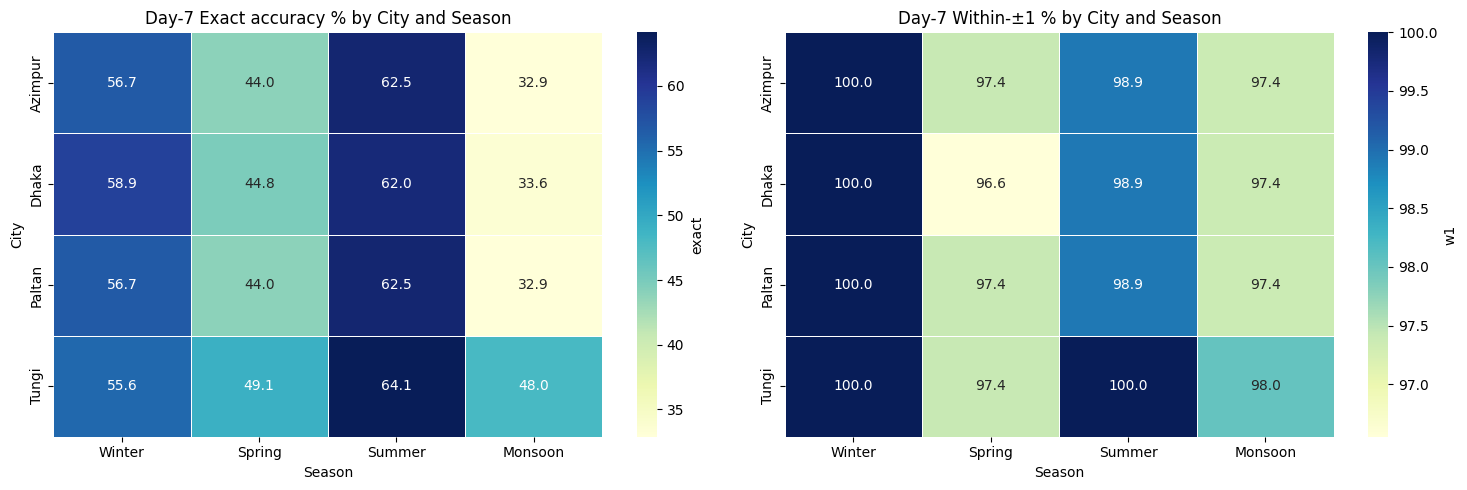

In [15]:
# CELL 15 — FIGURE 10: Per-city per-season heatmap
rows = []
for city in CITIES:
    b = bt[city]['aqi'].copy()
    b['month'] = pd.to_datetime(b['date']).dt.month
    b['season'] = b['month'].apply(season_of)
    for season in ['Winter','Spring','Summer','Monsoon']:
        for h in [1, 7, 30]:
            s = b[(b.season == season) & (b.h == h)]
            if len(s):
                m = cat_metrics(s.actual.values, s.model.values)
                rows.append({'city':city,'season':season,'horizon':h,'exact':m['exact'],'w1':m['w1']})
df_heat = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in [(axes[0], 'exact', 'Exact accuracy %'), (axes[1], 'w1', 'Within-±1 %')]:
    pivot = df_heat[df_heat.horizon == 7].pivot(index='city', columns='season', values=metric)
    pivot = pivot[['Winter','Spring','Summer','Monsoon']]
    sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax, cbar_kws={'label': metric}, linewidths=0.5)
    ax.set_title(f'Day-7 {title} by City and Season')
    ax.set_xlabel('Season'); ax.set_ylabel('City')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_10_heatmap.png', bbox_inches='tight'); plt.show()

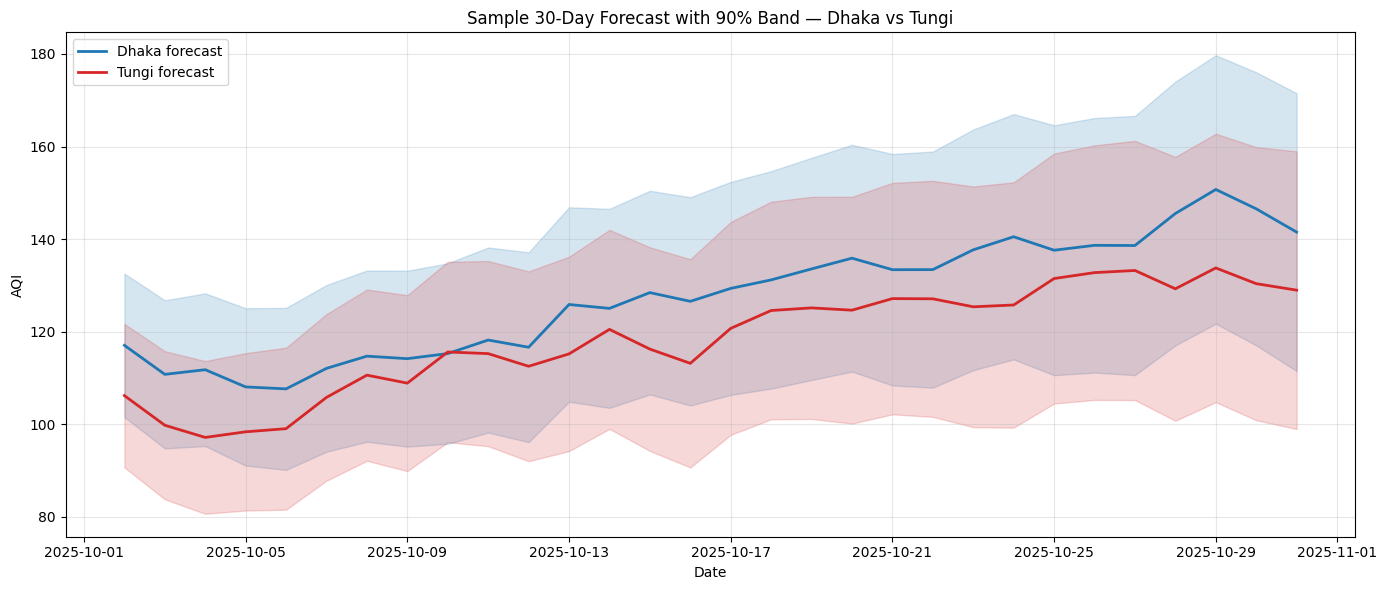

In [16]:
# CELL 16 — FIGURE 11: Sample 30-day forecast with band (Tungi vs Dhaka)
today = pd.Timestamp('2025-10-01')
fig, ax = plt.subplots(figsize=(14, 6))
for city, col in [('Dhaka','#1f77b4'), ('Tungi','#d62728')]:
    fm = final_daily[city]['aqi']
    recent = daily_by_city[city]['aqi'].loc[:today - pd.Timedelta(days=1)].tail(30)
    p = fm.predict(recent, today)
    ax.plot(p.index, p['forecast'], '-', color=col, linewidth=2, label=f'{city} forecast')
    ax.fill_between(p.index, p['low'], p['high'], color=col, alpha=0.18)
ax.set_xlabel('Date'); ax.set_ylabel('AQI')
ax.set_title('Sample 30-Day Forecast with 90% Band — Dhaka vs Tungi')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_11_sample_forecast.png', bbox_inches='tight'); plt.show()

In [17]:
# CELL 17 — SAVE BUNDLE
os.makedirs('atmos_bundle', exist_ok=True)
bundle = {
    'hourly_per_city': hourly_per_city,
    'daily_per_city': final_daily,
    'cities': CITIES, 'default_city': DEFAULT_CITY, 'levels': AQI_LEVELS,
    'trained_on': {'from': str(H.index.min()), 'to': str(H.index.max())},
    'split': {'val_start': VAL_START, 'test_start': TEST_START, 'bt_start': BT_START},
    'metrics': {city: {str(h): {'exact': float(per_city_reports[city].loc[h,'model_exact']),
                                  'w1': float(per_city_reports[city].loc[h,'model_w1']),
                                  'MAE': float(per_city_reports[city].loc[h,'MAE'])}
                        for h in [1,7,30] if h in per_city_reports[city].index}
                for city in CITIES},
    'version': 'atmos-final-' + pd.Timestamp.now().strftime('%Y%m%d-%H%M'),
}
joblib.dump(bundle, BUNDLE, compress=3)
print(f'Bundle: {os.path.getsize(BUNDLE)//1024} KB | version {bundle["version"]}')
print(f'Figures saved in {FIGDIR}/')
for f in sorted(os.listdir(FIGDIR)): print(f'  {f}')

Bundle: 137903 KB | version atmos-final-20261005-2015
Figures saved in figures/
  fig_10_heatmap.png
  fig_11_sample_forecast.png
  fig_1_5_hourly_accuracy.png
  fig_2_distribution.png
  fig_3_monthly_location.png
  fig_4_corr_matrix.png
  fig_6_confusion.png
  fig_7_feature_importance.png
  fig_8_daily_perf.png
  fig_9_residuals.png


In [18]:
# CELL 18 — FASTAPI SERVER (location-aware) — Full code
TZ = ZoneInfo('Asia/Dhaka')
if os.path.exists(DB_PATH): os.remove(DB_PATH)
conn = sqlite3.connect(DB_PATH, check_same_thread=False); lock = threading.RLock()
conn.execute('''CREATE TABLE IF NOT EXISTS samples(
    device_id TEXT, location TEXT, ts REAL, pm2_5 REAL, pm10 REAL, carbon_monoxide REAL,
    nitrogen_dioxide REAL, sulphur_dioxide REAL, ozone REAL, UNIQUE(device_id, ts))''')
conn.commit()
FT3_TO_M3=0.0283168466; CFM_TO_M3H=1.699011
PM25_AT_AQI={50:12.0,100:35.4,150:55.4,200:150.4}
SCENARIOS={'indoor_sealed':dict(lam=0.3,pen=0.7,k=0.15,desc='Indoor sealed'),
           'indoor_normal':dict(lam=0.7,pen=0.8,k=0.10,desc='Indoor normal'),
           'indoor_windows_open':dict(lam=3.0,pen=1.0,k=0.10,desc='Windows open'),
           'outdoor_semi_open':dict(lam=8.0,pen=1.0,k=0.0,desc='Semi-open'),
           'outdoor_open':dict(lam=20.,pen=1.0,k=0.0,desc='Open air')}
def room_volume_m3(a,h): return float(a)*float(h)*FT3_TO_M3
def devices_needed(pm25_out, sc, vol, cadr, target_pm25=35.4, hours=24.0, max_d=60):
    p=SCENARIOS[sc]; lam,pen,k=p['lam'],p['pen'],p['k']
    c0=pen*lam/(lam+k)*pm25_out
    if c0<=target_pm25: return {'n':0,'note':'Already within target'}
    q=cadr*CFM_TO_M3H/vol
    for n in range(1,max_d+1):
        rate=lam+k+n*q; css=pen*lam*pm25_out/rate; ct=css+(c0-css)*np.exp(-rate*hours)
        if ct<=target_pm25: return {'n':n,'note':''}
    return {'n':None,'note':f'Not reachable in {hours}h'}
class Reading(BaseModel):
    device_id: str; location: str; observed_at: datetime
    pm2_5: float | None = None; pm10: float | None = None; carbon_monoxide: float | None = None
    nitrogen_dioxide: float | None = None; sulphur_dioxide: float | None = None; ozone: float | None = None
def normalize_city(loc):
    if loc in CITIES: return loc
    for c in CITIES:
        if c.lower()==str(loc).lower(): return c
    return DEFAULT_CITY
api = FastAPI(title='ATMOS Location-Aware API', version=bundle['version'])
api.add_middleware(CORSMiddleware, allow_origins=['*'], allow_methods=['GET','POST'], allow_headers=['*'])
@api.get('/healthz')
def health(): return {'ok':True,'model_version':bundle['version'],'cities':CITIES,'time':datetime.now(TZ).isoformat()}
@api.post('/api/v1/readings')
def ingest(r: Reading, x_api_key: str = Header(default='')):
    if DEVICE_KEYS.get(r.device_id) != x_api_key: raise HTTPException(403, 'bad key')
    if r.observed_at.tzinfo is None: raise HTTPException(422, 'need tz')
    age = datetime.now(TZ).timestamp() - r.observed_at.timestamp()
    if age < -120: raise HTTPException(422, 'future')
    if age > MAX_READING_AGE_S: raise HTTPException(422, 'old')
    vals = []
    for p in POLLUTANTS:
        v = getattr(r, p)
        if v is not None and (not np.isfinite(v) or v < 0 or v > POLLUTANT_LIMITS[p]): v = None
        vals.append(v)
    if all(v is None for v in vals): raise HTTPException(422, 'no valid')
    city = normalize_city(r.location)
    with lock:
        cur = conn.execute('INSERT OR IGNORE INTO samples VALUES(?,?,?,?,?,?,?,?,?)',
                           (r.device_id, city, r.observed_at.timestamp(), *vals)); conn.commit()
    return {'accepted': True, 'duplicate': cur.rowcount == 0, 'location': city}
def _hourly_frame(device_id, city=None):
    with lock:
        if city: rows = conn.execute('SELECT ts,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone FROM samples WHERE device_id=? AND location=? ORDER BY ts', (device_id, city)).fetchall()
        else: rows = conn.execute('SELECT ts,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone FROM samples WHERE device_id=? ORDER BY ts', (device_id,)).fetchall()
    if not rows: return pd.DataFrame(columns=POLLUTANTS, dtype=float)
    d = pd.DataFrame(rows, columns=['ts']+POLLUTANTS)
    idx = pd.DatetimeIndex(pd.to_datetime(d.pop('ts'), unit='s', utc=True)).tz_convert(TZ).tz_localize(None)
    d.index = idx; g = d.groupby(idx.floor('h'))
    mean = g[POLLUTANTS].mean(); cnt = g[POLLUTANTS].count()
    mean = mean.where(cnt >= MIN_SAMPLES_PER_HOUR)
    cur_hour = pd.Timestamp(datetime.now(TZ).replace(tzinfo=None)).floor('h')
    return mean[mean.index < cur_hour]
@api.get('/api/v1/forecast/hourly')
def hourly_ep(device_id: str, location: str = DEFAULT_CITY, x_api_key: str = Header(default='')):
    if x_api_key != READ_KEY: raise HTTPException(401, 'bad read key')
    city = normalize_city(location); hf = _hourly_frame(device_id, city).dropna(subset=POLLUTANTS)
    resp = {'device_id': device_id, 'location': city, 'status': 'warming_up', 'hours_available': len(hf), 'hours_required': 25, 'current': None, 'forecasts': []}
    if len(hf) == 0: resp['message'] = 'No data'; return resp
    run = hf.tail(25); last = run.iloc[-1]
    aqi_now = float(compute_aqi(**{p: float(last[p]) for p in POLLUTANTS}))
    pm25_now = float(last['pm2_5']) if pd.notna(last['pm2_5']) else None
    pm10_now = float(last['pm10']) if pd.notna(last['pm10']) else None
    cur = aqi_to_level(aqi_now); cur['hour_start'] = run.index[-1].isoformat()
    cur['pm2_5'] = round(pm25_now,1) if pm25_now is not None else None
    cur['pm10'] = round(pm10_now,1) if pm10_now is not None else None
    resp['current'] = cur
    if len(run) < 25: resp['message'] = f'Collecting {len(run)}/25'; return resp
    F_row = hourly_features(run); cm = hourly_per_city[city]
    for col in cm['features']:
        if col not in F_row.columns: F_row[col] = 0
    X = F_row[cm['features']].iloc[[-1]]; fc = []
    for hz in (1,3,6):
        d_aqi = [float(b.predict(X)[0]) for b in cm['aqi'][hz]]
        pred_aqi = float(np.clip(aqi_now + np.mean(d_aqi), 0, 500))
        pred_pm25 = None; pred_pm10 = None
        if pm25_now is not None and hz in cm.get('pm2_5',{}):
            d_pm = [float(b.predict(X)[0]) for b in cm['pm2_5'][hz]]
            pred_pm25 = round(float(np.clip(pm25_now + np.mean(d_pm), 0, 500)), 1)
        if pm10_now is not None and hz in cm.get('pm10',{}):
            d_p10 = [float(b.predict(X)[0]) for b in cm['pm10'][hz]]
            pred_pm10 = round(float(np.clip(pm10_now + np.mean(d_p10), 0, 1000)), 1)
        e = aqi_to_level(pred_aqi); e['horizon_hours'] = hz
        e['hour_start'] = (run.index[-1] + pd.Timedelta(hours=hz)).isoformat()
        e['change_from_current'] = round(pred_aqi - aqi_now, 1)
        e['trend'] = ('worsening' if pred_aqi-aqi_now > 5 else 'improving' if pred_aqi-aqi_now < -5 else 'stable')
        e['pm2_5'] = pred_pm25; e['pm10'] = pred_pm10
        fc.append(e)
    resp['status'] = 'ok'; resp['forecasts'] = fc; return resp
@api.get('/api/v1/forecast/daily')
def daily_ep(device_id: str, location: str = DEFAULT_CITY, days: int = 30, x_api_key: str = Header(default='')):
    if x_api_key != READ_KEY: raise HTTPException(401, 'bad read key')
    city = normalize_city(location); hf = _hourly_frame(device_id, city)
    today = pd.Timestamp(datetime.now(TZ).replace(tzinfo=None)).normalize()
    if len(hf) > 0:
        full = hf.reindex(pd.date_range(hf.index.min(), hf.index.max(), freq='h'))
        full['aqi'] = compute_aqi(**{p: full[p].values for p in POLLUTANTS})
        g = full.resample('D')
        d = pd.DataFrame({'aqi':g['aqi'].mean(),'pm2_5':g['pm2_5'].mean(),'pm10':g['pm10'].mean()})
        d.loc[g['aqi'].count() < MIN_SAMPLES_PER_HOUR, ['aqi','pm2_5','pm10']] = np.nan
        d = d[d.index < today]
    else:
        d = pd.DataFrame(columns=['aqi','pm2_5','pm10'], dtype=float)
    n_hist = int(d['aqi'].notna().sum()) if len(d) else 0
    origin = today - pd.Timedelta(days=1)
    ra = d['aqi'] if n_hist>=3 else d['aqi'].iloc[0:0]
    rp = d['pm2_5'] if n_hist>=3 else d['pm2_5'].iloc[0:0]
    r10 = d['pm10'] if n_hist>=3 else d['pm10'].iloc[0:0]
    p_aqi = final_daily[city]['aqi'].predict(ra, origin).iloc[:days]
    p_pm  = final_daily[city]['pm2_5'].predict(rp, origin).iloc[:days]
    p_p10 = final_daily[city]['pm10'].predict(r10, origin).iloc[:days]
    items = []
    for i in range(len(p_aqi)):
        lv = aqi_to_level(p_aqi['forecast'].iloc[i])
        items.append({'date': p_aqi.index[i].date().isoformat(), 'day': i+1,
                      'aqi': lv['aqi'], 'level': lv['level'], 'level_index': lv['level_index'],
                      'color': lv['color'], 'advice': lv['advice'],
                      'aqi_low': round(float(p_aqi['low'].iloc[i]),1),
                      'aqi_high': round(float(p_aqi['high'].iloc[i]),1),
                      'pm2_5': round(float(p_pm['forecast'].iloc[i]),1),
                      'pm2_5_low': round(float(p_pm['low'].iloc[i]),1),
                      'pm2_5_high': round(float(p_pm['high'].iloc[i]),1),
                      'pm10': round(float(p_p10['forecast'].iloc[i]),1),
                      'pm10_low': round(float(p_p10['low'].iloc[i]),1),
                      'pm10_high': round(float(p_p10['high'].iloc[i]),1)})
    return {'device_id': device_id, 'location': city,
            'basis': 'live_sensor_history' if n_hist>=3 else 'seasonal_only',
            'history_days_used': n_hist, 'forecast': items}
@api.get('/api/v1/device-requirement')
def device_requirement(device_id: str, location: str = DEFAULT_CITY, scenario: str = 'indoor_normal',
                       target_aqi: int = 100, hours: float = 24, area_ft2: float = 700,
                       height_ft: float = 10, cadr_cfm: float = 120, x_api_key: str = Header(default='')):
    if x_api_key != READ_KEY: raise HTTPException(401, 'bad read key')
    if scenario not in SCENARIOS: raise HTTPException(422, 'bad scenario')
    if target_aqi not in PM25_AT_AQI: raise HTTPException(422, 'bad target')
    city = normalize_city(location); target_pm25 = PM25_AT_AQI[target_aqi]; vol = room_volume_m3(area_ft2, height_ft)
    hf = _hourly_frame(device_id, city); today = pd.Timestamp(datetime.now(TZ).replace(tzinfo=None)).normalize()
    if len(hf) > 0:
        full = hf.reindex(pd.date_range(hf.index.min(), hf.index.max(), freq='h'))
        full['aqi'] = compute_aqi(**{p: full[p].values for p in POLLUTANTS})
        g = full.resample('D'); d = pd.DataFrame({'aqi':g['aqi'].mean(),'pm2_5':g['pm2_5'].mean(),'pm10':g['pm10'].mean()})
        d.loc[g['aqi'].count() < MIN_SAMPLES_PER_HOUR, ['aqi','pm2_5','pm10']] = np.nan; d = d[d.index < today]
    else: d = pd.DataFrame(columns=['aqi','pm2_5','pm10'], dtype=float)
    n_hist = int(d['aqi'].notna().sum()) if len(d) else 0; origin = today - pd.Timedelta(days=1)
    recent = d['pm2_5'] if n_hist>=3 else d['pm2_5'].iloc[0:0]
    pm_fc = final_daily[city]['pm2_5'].predict(recent, origin).iloc[:30]
    days_out = []; typical = []
    for i in range(len(pm_fc)):
        pm_val = float(pm_fc['forecast'].iloc[i]); pm_hi = float(pm_fc['high'].iloc[i])
        r = devices_needed(pm_val, scenario, vol, cadr_cfm, target_pm25, hours)
        r_hi = devices_needed(pm_hi, scenario, vol, cadr_cfm, target_pm25, hours)
        days_out.append({'date': pm_fc.index[i].date().isoformat(),'day':i+1,
                         'forecast_outdoor_pm2_5':round(pm_val,1),
                         'forecast_high_case_pm2_5':round(pm_hi,1),
                         'devices_needed':r['n'],'devices_needed_high_case':r_hi['n'],'note':r['note']})
        if r['n'] is not None: typical.append(r['n'])
    return {'device_id': device_id, 'location': city,
            'room': {'area_ft2': area_ft2, 'height_ft': height_ft, 'volume_m3': round(vol,1)},
            'device_cadr_cfm': cadr_cfm, 'scenario': scenario, 'scenario_description': SCENARIOS[scenario]['desc'],
            'target': {'aqi': target_aqi, 'pm2_5': target_pm25, 'within_hours': hours},
            'basis': 'live_sensor_history' if n_hist>=3 else 'seasonal_only', 'history_days_used': n_hist,
            'summary': {'typical_devices': int(np.median(typical)) if typical else None,
                        'max_devices_forecast': max(typical) if typical else None,
                        'max_devices_high_case': max([d['devices_needed_high_case'] or 0 for d in days_out]) if days_out else None},
            'days': days_out, 'disclaimer': 'Physics model with assumed air-exchange values.'}
print('API defined.')
config = uvicorn.Config(api, host='0.0.0.0', port=8000, log_level='warning')
server = uvicorn.Server(config)
threading.Thread(target=server.run, daemon=True).start(); time.sleep(3)
print(f'✅ Server: http://localhost:8000 | Cities: {CITIES}')

API defined.
✅ Server: http://localhost:8000 | Cities: ['Azimpur', 'Dhaka', 'Paltan', 'Tungi']


In [19]:
# CELL 19 — GENERATE serve.py + requirements.txt
SERVE_PY = open('atmos_serve_template.txt','w') if False else None
serve_code = '''"""ATMOS Location-Aware API — Render deployment."""
import os, sqlite3, threading, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, uvicorn
import lightgbm as lgb
from sklearn.linear_model import Ridge
from datetime import datetime
from zoneinfo import ZoneInfo
from fastapi import FastAPI, Header, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel

BUNDLE_PATH = os.environ.get('ATMOS_BUNDLE_PATH', 'atmos_bundle/bundle.joblib')
DB_PATH     = os.environ.get('ATMOS_DB_PATH', 'atmos_live.db')
PORT        = int(os.environ.get('PORT', 8000))
bundle = joblib.load(BUNDLE_PATH)
hourly_per_city = bundle['hourly_per_city']
final_daily = bundle['daily_per_city']
CITIES = bundle['cities']
DEFAULT_CITY = bundle.get('default_city', 'Dhaka')
AQI_LEVELS = bundle['levels']
DEVICE_KEYS = {'device1': os.environ.get('ATMOS_DEVICE_KEY', 'sensor-key-change-me')}
READ_KEY = os.environ.get('ATMOS_READ_KEY', 'frontend-read-key-change-me')
POLLUTANTS = ['pm2_5','pm10','carbon_monoxide','nitrogen_dioxide','sulphur_dioxide','ozone']
POLLUTANT_LIMITS = {'pm2_5':1000,'pm10':2000,'carbon_monoxide':60000,'nitrogen_dioxide':3000,'sulphur_dioxide':3000,'ozone':1000}
MIN_SAMPLES_PER_HOUR = 1; MAX_READING_AGE_S = 21600
FT3_TO_M3=0.0283168466; CFM_TO_M3H=1.699011
TZ = ZoneInfo('Asia/Dhaka')
_EDGES = np.array([50,100,150,200,300])
_BP = {'pm2_5':[(0.0,12.0,0,50),(12.1,35.4,51,100),(35.5,55.4,101,150),(55.5,150.4,151,200),(150.5,250.4,201,300),(250.5,350.4,301,400),(350.5,500.4,401,500)],'pm10':[(0,54,0,50),(55,154,51,100),(155,254,101,150),(255,354,151,200),(355,424,201,300),(425,504,301,400),(505,604,401,500)],'co':[(0.0,4.4,0,50),(4.5,9.4,51,100),(9.5,12.4,101,150),(12.5,15.4,151,200),(15.5,30.4,201,300),(30.5,40.4,301,400),(40.5,50.4,401,500)],'so2':[(0,35,0,50),(36,75,51,100),(76,185,101,150),(186,304,151,200),(305,604,201,300),(605,804,301,400),(805,1004,401,500)],'no2':[(0,53,0,50),(54,100,51,100),(101,360,101,150),(361,649,151,200),(650,1249,201,300),(1250,1649,301,400),(1650,2049,401,500)],'o3':[(0.000,0.054,0,50),(0.055,0.070,51,100),(0.071,0.085,101,150),(0.086,0.105,151,200),(0.106,0.200,201,300)]}
_TRUNC = {'pm2_5':1,'pm10':0,'co':1,'so2':0,'no2':0,'o3':3}; _DIV = {'co':1145.0,'no2':1.882,'so2':2.620,'o3':1963.0}
def _trunc(x,d): f=10.0**d; return np.round(np.floor(np.asarray(x,float)*f+1e-9)/f,d)
def _sub(c,n):
    c=np.asarray(c,float); b=_BP[n]
    lo=np.array([x[0] for x in b]); hi=np.array([x[1] for x in b])
    ilo=np.array([x[2] for x in b],float); ihi=np.array([x[3] for x in b],float)
    i=np.clip(np.searchsorted(lo,c,side='right')-1,0,len(b)-1)
    return np.where(np.isnan(c),np.nan,(ihi[i]-ilo[i])/(hi[i]-lo[i])*(c-lo[i])+ilo[i])
def compute_aqi(**kw):
    m={'pm2_5':kw.get('pm2_5'),'pm10':kw.get('pm10'),'co':kw.get('carbon_monoxide'),'no2':kw.get('nitrogen_dioxide'),'so2':kw.get('sulphur_dioxide'),'o3':kw.get('ozone')}
    ss=[]
    for n,v in m.items():
        if v is None: continue
        x=np.asarray(v,float); x=np.where(np.isfinite(x)&(x>=0),x,np.nan)
        if n in _DIV: x=x/_DIV[n]
        x=_trunc(x,_TRUNC[n]); x=np.where(x<=_BP[n][-1][1],x,np.nan); ss.append(_sub(x,n))
    if not ss: return float('nan')
    st=np.stack(np.broadcast_arrays(*ss),axis=0); an=np.all(np.isnan(st),axis=0)
    a=np.floor(np.where(np.isnan(st),-1,st).max(axis=0)+0.5); return float(np.where(an,np.nan,a))
def aqi_to_level(aqi):
    aqi=float(aqi)
    if not np.isfinite(aqi) or aqi<0: return {'aqi':None,'level':None,'level_index':-1,'color':None,'advice':None}
    idx=int(np.searchsorted(_EDGES, np.floor(aqi+0.5), side='left')); idx=max(0,min(idx,5))
    return {'aqi':round(aqi,1),'level':AQI_LEVELS[idx]['level'],'level_index':idx,'color':AQI_LEVELS[idx]['color'],'advice':AQI_LEVELS[idx]['advice']}
def normalize_city(loc):
    if loc in CITIES: return loc
    for c in CITIES:
        if c.lower()==str(loc).lower(): return c
    return DEFAULT_CITY
conn=sqlite3.connect(DB_PATH,check_same_thread=False); lock=threading.RLock()
conn.execute("CREATE TABLE IF NOT EXISTS samples(device_id TEXT, location TEXT, ts REAL, pm2_5 REAL, pm10 REAL, carbon_monoxide REAL, nitrogen_dioxide REAL, sulphur_dioxide REAL, ozone REAL, UNIQUE(device_id, ts))"); conn.commit()
PM25_AT_AQI={50:12.0,100:35.4,150:55.4,200:150.4}
SCENARIOS={'indoor_sealed':dict(lam=0.3,pen=0.7,k=0.15,desc='Sealed'),'indoor_normal':dict(lam=0.7,pen=0.8,k=0.10,desc='Normal'),'indoor_windows_open':dict(lam=3.0,pen=1.0,k=0.10,desc='Windows open'),'outdoor_semi_open':dict(lam=8.0,pen=1.0,k=0.0,desc='Semi-open'),'outdoor_open':dict(lam=20.,pen=1.0,k=0.0,desc='Open air')}
def room_volume_m3(a,h): return float(a)*float(h)*FT3_TO_M3
def devices_needed(pm25_out,sc,vol,cadr,target_pm25=35.4,hours=24.0,max_d=60):
    p=SCENARIOS[sc]; lam,pen,k=p['lam'],p['pen'],p['k']
    c0=pen*lam/(lam+k)*pm25_out
    if c0<=target_pm25: return {'n':0,'note':'Already within target'}
    q=cadr*CFM_TO_M3H/vol
    for n in range(1,max_d+1):
        rate=lam+k+n*q; css=pen*lam*pm25_out/rate; ct=css+(c0-css)*np.exp(-rate*hours)
        if ct<=target_pm25: return {'n':n,'note':''}
    return {'n':None,'note':f'Not reachable in {hours}h'}
def hourly_features(df):
    f=pd.DataFrame(index=df.index)
    for p in POLLUTANTS+['aqi']:
        s=df[p]; f[p]=s
        for lag in (1,2,3,6,12,24): f[f'{p}_lag{lag}']=s.shift(lag)
        for w in (3,6,24): f[f'{p}_mean{w}']=s.rolling(w,min_periods=w).mean()
        f[f'{p}_std6']=s.rolling(6,min_periods=6).std()
    f['aqi_d1']=df['aqi']-df['aqi'].shift(1); f['aqi_d3']=df['aqi']-df['aqi'].shift(3)
    h=df.index.hour; doy=df.index.dayofyear
    f['h_sin']=np.sin(2*np.pi*h/24); f['h_cos']=np.cos(2*np.pi*h/24)
    f['d_sin']=np.sin(2*np.pi*doy/365.25); f['d_cos']=np.cos(2*np.pi*doy/365.25); f['dow']=df.index.dayofweek
    return f
def _hourly_frame(device_id, city=None):
    with lock:
        if city: rows=conn.execute('SELECT ts,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone FROM samples WHERE device_id=? AND location=? ORDER BY ts',(device_id,city)).fetchall()
        else: rows=conn.execute('SELECT ts,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone FROM samples WHERE device_id=? ORDER BY ts',(device_id,)).fetchall()
    if not rows: return pd.DataFrame(columns=POLLUTANTS, dtype=float)
    d=pd.DataFrame(rows,columns=['ts']+POLLUTANTS)
    idx=pd.DatetimeIndex(pd.to_datetime(d.pop('ts'),unit='s',utc=True)).tz_convert(TZ).tz_localize(None)
    d.index=idx; g=d.groupby(idx.floor('h'))
    mean=g[POLLUTANTS].mean(); cnt=g[POLLUTANTS].count()
    mean=mean.where(cnt>=MIN_SAMPLES_PER_HOUR)
    cur=pd.Timestamp(datetime.now(TZ).replace(tzinfo=None)).floor('h')
    return mean[mean.index<cur]
class Reading(BaseModel):
    device_id: str; location: str; observed_at: datetime
    pm2_5: float | None = None; pm10: float | None = None; carbon_monoxide: float | None = None
    nitrogen_dioxide: float | None = None; sulphur_dioxide: float | None = None; ozone: float | None = None
api=FastAPI(title='ATMOS API',version=bundle['version'])
api.add_middleware(CORSMiddleware,allow_origins=['*'],allow_methods=['GET','POST'],allow_headers=['*'])
@api.get('/healthz')
def health(): return {'ok':True,'model_version':bundle['version'],'cities':CITIES,'time':datetime.now(TZ).isoformat()}
@api.post('/api/v1/readings')
def ingest(r:Reading,x_api_key:str=Header(default='')):
    if DEVICE_KEYS.get(r.device_id)!=x_api_key: raise HTTPException(403,'bad key')
    if r.observed_at.tzinfo is None: raise HTTPException(422,'need tz')
    age=datetime.now(TZ).timestamp()-r.observed_at.timestamp()
    if age<-120: raise HTTPException(422,'future')
    if age>MAX_READING_AGE_S: raise HTTPException(422,'old')
    vals=[]
    for p in POLLUTANTS:
        v=getattr(r,p)
        if v is not None and (not np.isfinite(v) or v<0 or v>POLLUTANT_LIMITS[p]): v=None
        vals.append(v)
    if all(v is None for v in vals): raise HTTPException(422,'no valid')
    city=normalize_city(r.location)
    with lock:
        cur=conn.execute('INSERT OR IGNORE INTO samples VALUES(?,?,?,?,?,?,?,?,?)',(r.device_id,city,r.observed_at.timestamp(),*vals)); conn.commit()
    return {'accepted':True,'duplicate':cur.rowcount==0,'location':city}
@api.get('/api/v1/forecast/hourly')
def hourly_ep(device_id:str,location:str=DEFAULT_CITY,x_api_key:str=Header(default='')):
    if x_api_key!=READ_KEY: raise HTTPException(401,'bad read key')
    city=normalize_city(location); hf=_hourly_frame(device_id,city).dropna(subset=POLLUTANTS)
    resp={'device_id':device_id,'location':city,'status':'warming_up','hours_available':len(hf),'hours_required':25,'current':None,'forecasts':[]}
    if len(hf)==0: resp['message']='No data'; return resp
    run=hf.tail(25); last=run.iloc[-1]
    aqi_now=float(compute_aqi(**{p:float(last[p]) for p in POLLUTANTS}))
    pm25_now=float(last['pm2_5']) if pd.notna(last['pm2_5']) else None
    pm10_now=float(last['pm10']) if pd.notna(last['pm10']) else None
    cur=aqi_to_level(aqi_now); cur['hour_start']=run.index[-1].isoformat()
    cur['pm2_5']=round(pm25_now,1) if pm25_now is not None else None
    cur['pm10']=round(pm10_now,1) if pm10_now is not None else None
    resp['current']=cur
    if len(run)<25: resp['message']=f'Collecting {len(run)}/25'; return resp
    F_row=hourly_features(run); cm=hourly_per_city[city]
    for col in cm['features']:
        if col not in F_row.columns: F_row[col]=0
    X=F_row[cm['features']].iloc[[-1]]; fc=[]
    for hz in (1,3,6):
        d_aqi=[float(b.predict(X)[0]) for b in cm['aqi'][hz]]
        pred_aqi=float(np.clip(aqi_now+np.mean(d_aqi),0,500))
        pred_pm25=None; pred_pm10=None
        if pm25_now is not None and hz in cm.get('pm2_5',{}):
            d_pm=[float(b.predict(X)[0]) for b in cm['pm2_5'][hz]]
            pred_pm25=round(float(np.clip(pm25_now+np.mean(d_pm),0,500)),1)
        if pm10_now is not None and hz in cm.get('pm10',{}):
            d_p10=[float(b.predict(X)[0]) for b in cm['pm10'][hz]]
            pred_pm10=round(float(np.clip(pm10_now+np.mean(d_p10),0,1000)),1)
        e=aqi_to_level(pred_aqi); e['horizon_hours']=hz
        e['hour_start']=(run.index[-1]+pd.Timedelta(hours=hz)).isoformat()
        e['change_from_current']=round(pred_aqi-aqi_now,1)
        e['trend']='worsening' if pred_aqi-aqi_now>5 else 'improving' if pred_aqi-aqi_now<-5 else 'stable'
        e['pm2_5']=pred_pm25; e['pm10']=pred_pm10; fc.append(e)
    resp['status']='ok'; resp['forecasts']=fc; return resp
@api.get('/api/v1/forecast/daily')
def daily_ep(device_id:str,location:str=DEFAULT_CITY,days:int=30,x_api_key:str=Header(default='')):
    if x_api_key!=READ_KEY: raise HTTPException(401,'bad read key')
    city=normalize_city(location); hf=_hourly_frame(device_id,city)
    today=pd.Timestamp(datetime.now(TZ).replace(tzinfo=None)).normalize()
    if len(hf)>0:
        full=hf.reindex(pd.date_range(hf.index.min(),hf.index.max(),freq='h'))
        full['aqi']=compute_aqi(**{p:full[p].values for p in POLLUTANTS})
        g=full.resample('D'); d=pd.DataFrame({'aqi':g['aqi'].mean(),'pm2_5':g['pm2_5'].mean(),'pm10':g['pm10'].mean()})
        d.loc[g['aqi'].count()<MIN_SAMPLES_PER_HOUR,['aqi','pm2_5','pm10']]=np.nan; d=d[d.index<today]
    else: d=pd.DataFrame(columns=['aqi','pm2_5','pm10'],dtype=float)
    n_hist=int(d['aqi'].notna().sum()) if len(d) else 0; origin=today-pd.Timedelta(days=1)
    ra=d['aqi'] if n_hist>=3 else d['aqi'].iloc[0:0]; rp=d['pm2_5'] if n_hist>=3 else d['pm2_5'].iloc[0:0]; r10=d['pm10'] if n_hist>=3 else d['pm10'].iloc[0:0]
    p_aqi=final_daily[city]['aqi'].predict(ra,origin).iloc[:days]
    p_pm=final_daily[city]['pm2_5'].predict(rp,origin).iloc[:days]
    p_p10=final_daily[city]['pm10'].predict(r10,origin).iloc[:days]
    items=[]
    for i in range(len(p_aqi)):
        lv=aqi_to_level(p_aqi['forecast'].iloc[i])
        items.append({'date':p_aqi.index[i].date().isoformat(),'day':i+1,'aqi':lv['aqi'],'level':lv['level'],'level_index':lv['level_index'],'color':lv['color'],'advice':lv['advice'],'aqi_low':round(float(p_aqi['low'].iloc[i]),1),'aqi_high':round(float(p_aqi['high'].iloc[i]),1),'pm2_5':round(float(p_pm['forecast'].iloc[i]),1),'pm2_5_low':round(float(p_pm['low'].iloc[i]),1),'pm2_5_high':round(float(p_pm['high'].iloc[i]),1),'pm10':round(float(p_p10['forecast'].iloc[i]),1),'pm10_low':round(float(p_p10['low'].iloc[i]),1),'pm10_high':round(float(p_p10['high'].iloc[i]),1)})
    return {'device_id':device_id,'location':city,'basis':'live_sensor_history' if n_hist>=3 else 'seasonal_only','history_days_used':n_hist,'forecast':items}
@api.get('/api/v1/device-requirement')
def device_requirement(device_id:str,location:str=DEFAULT_CITY,scenario:str='indoor_normal',target_aqi:int=100,hours:float=24,area_ft2:float=700,height_ft:float=10,cadr_cfm:float=120,x_api_key:str=Header(default='')):
    if x_api_key!=READ_KEY: raise HTTPException(401,'bad read key')
    if scenario not in SCENARIOS: raise HTTPException(422,'bad scenario')
    if target_aqi not in PM25_AT_AQI: raise HTTPException(422,'bad target')
    city=normalize_city(location); target_pm25=PM25_AT_AQI[target_aqi]; vol=room_volume_m3(area_ft2,height_ft)
    hf=_hourly_frame(device_id,city); today=pd.Timestamp(datetime.now(TZ).replace(tzinfo=None)).normalize()
    if len(hf)>0:
        full=hf.reindex(pd.date_range(hf.index.min(),hf.index.max(),freq='h'))
        full['aqi']=compute_aqi(**{p:full[p].values for p in POLLUTANTS})
        g=full.resample('D'); d=pd.DataFrame({'aqi':g['aqi'].mean(),'pm2_5':g['pm2_5'].mean(),'pm10':g['pm10'].mean()})
        d.loc[g['aqi'].count()<MIN_SAMPLES_PER_HOUR,['aqi','pm2_5','pm10']]=np.nan; d=d[d.index<today]
    else: d=pd.DataFrame(columns=['aqi','pm2_5','pm10'],dtype=float)
    n_hist=int(d['aqi'].notna().sum()) if len(d) else 0; origin=today-pd.Timedelta(days=1)
    recent=d['pm2_5'] if n_hist>=3 else d['pm2_5'].iloc[0:0]
    pm_fc=final_daily[city]['pm2_5'].predict(recent,origin).iloc[:30]
    days_out=[]; typical=[]
    for i in range(len(pm_fc)):
        pm_val=float(pm_fc['forecast'].iloc[i]); pm_hi=float(pm_fc['high'].iloc[i])
        r=devices_needed(pm_val,scenario,vol,cadr_cfm,target_pm25,hours)
        r_hi=devices_needed(pm_hi,scenario,vol,cadr_cfm,target_pm25,hours)
        days_out.append({'date':pm_fc.index[i].date().isoformat(),'day':i+1,'forecast_outdoor_pm2_5':round(pm_val,1),'forecast_high_case_pm2_5':round(pm_hi,1),'devices_needed':r['n'],'devices_needed_high_case':r_hi['n'],'note':r['note']})
        if r['n'] is not None: typical.append(r['n'])
    return {'device_id':device_id,'location':city,'room':{'area_ft2':area_ft2,'height_ft':height_ft,'volume_m3':round(vol,1)},'device_cadr_cfm':cadr_cfm,'scenario':scenario,'scenario_description':SCENARIOS[scenario]['desc'],'target':{'aqi':target_aqi,'pm2_5':target_pm25,'within_hours':hours},'basis':'live_sensor_history' if n_hist>=3 else 'seasonal_only','history_days_used':n_hist,'summary':{'typical_devices':int(np.median(typical)) if typical else None,'max_devices_forecast':max(typical) if typical else None,'max_devices_high_case':max([d['devices_needed_high_case'] or 0 for d in days_out]) if days_out else None},'days':days_out,'disclaimer':'Physics model with assumed air-exchange values.'}
if __name__=='__main__': uvicorn.run(api,host='0.0.0.0',port=PORT,log_level='info')
'''
REQ = 'fastapi>=0.111.0\nuvicorn[standard]>=0.29.0\nlightgbm>=4.3.0\nscikit-learn>=1.4.0\nnumpy>=1.26.0\npandas>=2.2.0\njoblib>=1.4.0\nrequests>=2.31.0\npydantic>=2.7.0\n'
with open('serve.py','w') as f: f.write(serve_code)
with open('requirements.txt','w') as f: f.write(REQ)
print('✅ serve.py + requirements.txt written')
print('Render deploy: pip install -r requirements.txt; python serve.py')

✅ serve.py + requirements.txt written
Render deploy: pip install -r requirements.txt; python serve.py
